# 17 — LDA passo per passo (versione didattica)

Questo notebook segue **una sola riga** di Multi-News (un cluster di 2-3 articoli + il riassunto
umano di riferimento) e mostra, un passaggio alla volta, come **LDA — Latent Dirichlet Allocation**
(Blei, Ng & Jordan, 2003) individua i **temi** di un cluster e li usa per scegliere le frasi di un
riassunto estrattivo, e come lo si valuta.

A differenza di [`notebooks/17_lda.ipynb`](../notebooks/17_lda.ipynb), che gira in batch su
migliaia di righe e salva solo i risultati, qui l'obiettivo è **capire**: ogni passaggio è spiegato,
calcolato "a mano" quando possibile (l'inferenza di θ, le quote, la selezione) e **verificato contro
l'implementazione del benchmark** (le `assert` garantiscono che quello che vedi qui sia esattamente
ciò che fa il codice di produzione). Alla fine (sezione 13) c'è un **confronto concettuale con LSA**
([notebook 15](15_lsa_didattico.ipynb)): i due metodi sembrano parenti stretti, ma ragionano in modo
diverso.

## Il workflow in una figura

```
documento (2-3 articoli)
      │  1. scelta della riga
      ▼
frasi  s₀ s₁ … s_{N-1}            ← 2. suddivisione in frasi
      │
      ▼
matrice frase × termine di CONTEGGI ← 3. bag-of-words (non TF-IDF)
      │
      ▼
LDA: β (topic → parole)             ← 4. i temi: distribuzioni di probabilità sulle parole
     θ (frase → topic)              ← 5. ogni frase è una miscela di temi (proporzioni che sommano a 1)
      │
      ▼
peso dei temi = Σ θ                 ← 6. quote di frasi per tema (allocazione proporzionale)
      │                                  dentro ogni tema: le frasi con θ più alto
      ├──► 7. (a parte) quanto è stabile? effetto di N_TOPICS e di random_state
      ▼
selezione                           ← 8. per MODALITA: 11 frasi oppure budget di parole
      │
      ▼
riassunto estrattivo                ← 9. frasi rimesse in ordine di documento (+ tetto a budget)
      │
      ▼
confronto con il riferimento        ← 10.
      │
      ▼
ROUGE / BLEU / METEOR               ← 11. metriche
      │
      ▼
interpretazione                     ← 12-13.
```

## L'idea in due righe
LDA immagina che ogni frase sia stata "scritta" mescolando alcuni **temi**, e che ogni tema sia una
**distribuzione di probabilità sulle parole**. Il fitting inverte il processo e stima, per ogni frase,
*quanto appartiene a ciascun tema*. Il riassunto si costruisce poi per **copertura**:

> le `N_SENTENCES` frasi si **ripartiscono tra i temi in proporzione al loro peso**, e dentro ogni
> tema si prendono le frasi che gli appartengono di più.

Nessun tema rilevante resta senza frasi: è l'obiettivo tipico della sintesi multi-documento (§3.6 del
documento-guida). Il benchmark ha **una sola variante** di LDA (slug `lda`), a differenza di LSA che ne ha due.

> Come LSA ([`15`](15_lsa_didattico.ipynb)) e Centroid+MMR ([`11`](11_centroid_mmr_didattico.ipynb)), e a
> differenza di TextRank/LexRank ([`01`](01_textrank_didattico.ipynb), [`02`](02_lexrank_didattico.ipynb)),
> qui non c'è grafo né PageRank. I passi 1-2 e 9-12 sono identici agli altri notebook didattici.

⚠️ **Una riga non è un benchmark.** Le metriche della sezione 11 riguardano un solo esempio e
servono a capire *come si calcolano*, non a stabilire quale metodo sia migliore (per questo
esistono i notebook di benchmark su 5.610 righe).

## 0. Preparazione
Importiamo le librerie e le funzioni condivise del progetto (`summ_utils`). Il notebook si può
lanciare dalla cartella `notebooks_didattici/` o dalla radice del repository. Gira tutto su CPU,
senza modelli da scaricare.

In [1]:
import sys
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display
from scipy.special import digamma
from sklearn.decomposition import LatentDirichletAllocation, TruncatedSVD
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

# radice del progetto: la cartella sopra notebooks_didattici/ (o la cwd se già alla radice)
_cwd = Path.cwd()
BASE = _cwd.parent if _cwd.name in ('notebooks_didattici', 'notebooks') else _cwd
sys.path.insert(0, str(BASE / 'notebooks'))

import summ_utils as su
from pyAutoSummarizer.base import psr

su.stile_grafici()
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 200)
plt.rcParams['figure.dpi'] = 110

P = su.percorsi_standard(BASE)
print('Radice del progetto:', BASE)

C:\Users\maccu\AppData\Roaming\Python\Python312\site-packages\requests\__init__.py:113: RequestsDependencyWarning: urllib3 (2.5.0) or chardet (7.6.0)/charset_normalizer (3.4.7) doesn't match a supported version!
  warnings.warn(


C:\Users\maccu\AppData\Roaming\Python\Python312\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Radice del progetto: C:\Users\maccu\OneDrive\Desktop\Master_Project


## 1. Selezione del testo di partenza
Multi-News è composto da *cluster*: ogni riga contiene **2-3 articoli** sullo stesso evento,
concatenati con il separatore `|||||`, e un **riassunto scritto da un umano** (il
*riferimento*, o *gold*). Lavoriamo sulla **split di test** (la stessa su cui il benchmark
valuta i metodi).

`ROW_ID` è l'indice globale della riga in `data/tab/complete.tab`. La riga predefinita
(**50492**) è stata scelta perché è breve (19 frasi): matrici e grafici restano **leggibili**.
Puoi cambiare `ROW_ID` con qualunque altra riga della split di test (50491-56100): il resto del
notebook si adatta (con documenti molto lunghi i grafici diventano però fitti).

**`N_TOPICS`** è il numero di temi che LDA cerca (5 nel benchmark; il codice lo limita al numero di
frasi). **`SEED`** è il `random_state` di LDA (42 nel benchmark): a differenza della SVD, il fitting di LDA
parte da un'inizializzazione casuale, quindi il seme conta (lo vedremo nella sezione 7).

**`MODALITA`** sceglie come viene fissata la **lunghezza** del riassunto:

| `MODALITA` | regola | corrisponde a |
|---|---|---|
| `'frasi'` | `N_SENTENCES` (= 11) frasi, ripartite fra i temi | ambito `test` del benchmark |
| `'budget'` | **parole** ripartite fra i temi, fino alla lunghezza in parole del riferimento, poi tetto a 1,25× | ambito `test_budgetref` (issue #16) |

⚠️ **LDA è diverso da LSA e dai metodi con un ordinamento**: non produce una classifica di frasi da
tagliare dove si vuole. La lunghezza entra *dentro* la selezione (le quote per tema), quindi 'frasi' e
'budget' non sono due tagli dello stesso ordine ma due allocazioni diverse (sezione 8).
Cambiando `MODALITA` le sezioni 8-12 si adattano; le due alternative restano comunque confrontabili
nelle tabelle delle sezioni 10 e 11.

In [2]:
ROW_ID = 50492          # riga della split di test (50491-56100)
# Come si decide la LUNGHEZZA del riassunto:
#   'frasi'  -> N_SENTENCES frasi ripartite fra i temi (benchmark ambito `test`)
#   'budget' -> parole ripartite fra i temi fino alla lunghezza del riferimento,
#               poi tetto a 1,25x (benchmark ambito `test_budgetref`, issue #16)
MODALITA = 'budget'
N_SENTENCES = 11        # usato se MODALITA == 'frasi' (mediana del corpus)
N_TOPICS = 5            # numero di temi LDA (come il benchmark)
SEED = 42               # random_state di LDA (come il benchmark)
STOP_WORDS = ['en']     # solo per la segmentazione con psr (come il benchmark)
assert MODALITA in ('frasi', 'budget'), "MODALITA deve essere 'frasi' oppure 'budget'"

import csv

PRIMO_ROW_ID_TEST = 50491          # le righe di test sono 50491-56100 in complete.tab
PERCORSO_TEST = P['complete_tab'].with_name('test.tab')   # solo split test (68 MB): basta e avanza

def carica_riga_test(row_id):
    """Legge UNA riga di test. Prima da data/tab/test.tab (leggero, ideale su Colab: row_id = 50491 + indice,
    allineamento verificato con complete.tab), altrimenti da complete.tab (690 MB)."""
    problemi = []
    if PERCORSO_TEST.exists():
        try:
            with open(PERCORSO_TEST, encoding='utf-8', newline='') as f:
                lettore = csv.reader(f, delimiter='\t')
                for _ in range(su.HEADER_LINES_TAB):
                    next(lettore)
                for i, riga in enumerate(lettore):
                    if i == row_id - PRIMO_ROW_ID_TEST:
                        documento, riassunto_umano = riga          # ValueError se la riga è corrotta
                        return {'row_id': row_id, 'split': 'test', 'document': documento, 'summary': riassunto_umano}
            problemi.append(f'{PERCORSO_TEST.name}: row_id {row_id} fuori dalla split di test (50491-56100)')
        except ValueError:
            problemi.append(f'{PERCORSO_TEST.name} è incompleto o corrotto (riga con un numero di colonne inatteso)')
    else:
        problemi.append(f'{PERCORSO_TEST} non trovato')
    if P['complete_tab'].exists():
        try:
            return next(es for es in su.itera_split(P['complete_tab'], 'test') if es['row_id'] == row_id)
        except (ValueError, StopIteration):
            problemi.append(f'{P["complete_tab"].name} è incompleto o corrotto')
    else:
        problemi.append(f'{P["complete_tab"]} non trovato')
    raise RuntimeError('Impossibile leggere la riga: ' + ' | '.join(problemi) + '.\n'
        'I file .tab del repository sono su Git LFS: un `git clone` senza LFS (o un upload interrotto su Colab) '
        'dà un puntatore di pochi byte o un file troncato. Soluzioni: `git lfs pull`, oppure carica '
        'data/tab/test.tab (68 MB) in <radice>/data/tab/.')

esempio = carica_riga_test(ROW_ID)

articoli = [a.strip() for a in esempio['document'].split('|||||')]
riferimento = su.pulisci_riferimento(esempio['summary'])

print(f"row_id {ROW_ID} | split: {esempio['split']} | articoli nel cluster: {len(articoli)}")
print(f"parole nel documento: {len(esempio['document'].split())} | parole nel riferimento: {len(riferimento.split())}")
for k, a in enumerate(articoli, 1):
    print(f"\n--- Articolo {k} ({len(a.split())} parole) ---")
    print(textwrap.fill(a[:500] + ' […]', 110))
print('\n=== RIASSUNTO DI RIFERIMENTO (umano) ===')
print(textwrap.fill(riferimento, 110))

row_id 50492 | split: test | articoli nel cluster: 2
parole nel documento: 664 | parole nel riferimento: 168

--- Articolo 1 (482 parole) ---
UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesperson
for gay rights overnight on Boing Boing     It’s time to clarify a few details about the controversial “Hey
Facebook what’s SO wrong with a pic of two men kissing?” story, as it now beginning to be reported in the
mainstream media, and not always correctly.     First of all, with regards to the picture:     The photo which
was used to illustrate my first post about the John Snow Kiss-In i […]

--- Articolo 2 (181 parole) ---
|| News ||     Page 1 of 1             UPDATED: A photo of two men kissing that was posted on a Facebook page
protesting a London pub’s decision to eject a same-sex couple for kissing has been removed by the social
networking site, an error, according to a rep for the company.         "The photo in question does not vi

**Cosa abbiamo visto.** Il documento è l'unione dei 2-3 articoli; il riferimento è molto più
breve ed è scritto in modo *astratto* (riformula), mentre LDA può solo **copiare frasi intere**
dal documento: per questo è *estrattivo*.

## 2. Suddivisione del testo in frasi
L'unità di analisi è la **frase**: ogni frase è un "documento" per LDA e un candidato del riassunto.
Passi, uguali a quelli del benchmark (`segmenta()` del notebook 17, la **stessa** segmentazione di
TextRank, LexRank, First-k, Centroid+MMR e LSA: il pool di candidati è identico per tutti gli estrattivi):

1. il separatore `|||||` tra articoli viene sostituito da un a capo (`su.prepara_documento`),
   altrimenti resterebbe dentro le "frasi";
2. `psr.summarization(...)` spezza il testo con una **espressione regolare**: taglia dopo
   `. ! ?` seguiti da spazio, **tranne** dopo abbreviazioni (`Mr`, `Dr`, `Prof`, `St`, mesi
   abbreviati, iniziali maiuscole come in "J. Smith");
3. si tengono le frasi **originali** (`s.original`, in ordine di documento) e si scartano le stringhe vuote.

Come in Centroid+MMR e in LSA, *non* si usa `s.corpus` (il testo pre-processato dalla libreria): il
pre-processing lo fa il vettorizzatore (sezione 3).

In [3]:
documento = su.prepara_documento(esempio['document'])
s = psr.summarization(documento, stop_words=['en'])

# identico a segmenta() del notebook 17
frasi = [f.strip() for f in getattr(s, 'original', []) if f and f.strip()]
N = len(frasi)
parole_frase = np.array([len(f.split()) for f in frasi])
print(f'Il documento è stato diviso in N = {N} frasi.\n')

tab_frasi = pd.DataFrame({'frase': range(N), 'parole': parole_frase,
                          'testo': [f[:105] + ('…' if len(f) > 105 else '') for f in frasi]}).set_index('frase')
display(tab_frasi)

Il documento è stato diviso in N = 19 frasi.



,parole,testo
frase,,
0,60,"UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesper…"
1,59,"First of all, with regards to the picture: \n \n The photo which was used to illustrate my first post about…"
2,23,I am not a regular viewer so I can’t say if the man on the right is an extra or an actual character
3,33,"This picture has itself caused scandal in the UK, as it was a gay kiss that was broadcast before the wate…"
4,21,"However, since this episode aired (October 2008) Christian now has a boyfriend and a few more gay kisses …"
5,25,"In relation to the John Snow Kiss-In event, I used this particular photo because I considered it to be qu…"
6,15,The photos I had considered using before I chose that one are much more racy
7,3,Oh the irony
8,37,"Secondly, the removal of the Facebook John Snow Kiss-In event: \n \n It turns out that the Facebook event f…"


**Cosa abbiamo visto.** Le frasi hanno lunghezze molto diverse (da pochissime parole a quasi 70) e sono
numerate `0 … N-1` nell'ordine in cui compaiono nel documento: questi numeri sono gli **indici** che useremo in
tutti i grafici. Tieni d'occhio la lunghezza: tornerà importante. Nota anche che la divisione è *euristica*:
titoli, didascalie o frasi senza punto finale possono diventare "frasi" a sé.

## 3. La matrice frase × termine (conteggi)
Come in LSA si parte da una matrice con **una riga per frase** e **una colonna per termine** del vocabolario
del cluster, ma qui il valore `X[i, t]` è il **numero di occorrenze** del termine `t` nella frase `i`
(*bag-of-words*), non un peso TF-IDF.

**Perché i conteggi.** LDA è un modello **probabilistico generativo di conteggi**: la sua verosimiglianza è
definita su occorrenze intere di parole ("la parola `w` è comparsa 2 volte"). I pesi frazionari del TF-IDF non
hanno un significato in quel modello. (La SVD di LSA, invece, è pura algebra e accetta qualunque pesatura.)
`CountVectorizer(stop_words='english')` fa minuscole, tokenizzazione e rimozione delle stop-word inglesi, per non
far dominare i temi da parole funzionali.

Matrice X: 19 frasi × 207 termini | celle diverse da zero: 7.5%  → matrice sparsa
Occorrenze totali (token) dopo le stop-word: 312 | per frase: min 2, mediana 14, max 36
Valore massimo di una cella: 3  → quasi tutti i termini compaiono una volta sola in una frase
✔ CountVectorizer e TfidfVectorizer riempiono le STESSE celle: cambia solo il peso (intero vs TF-IDF)


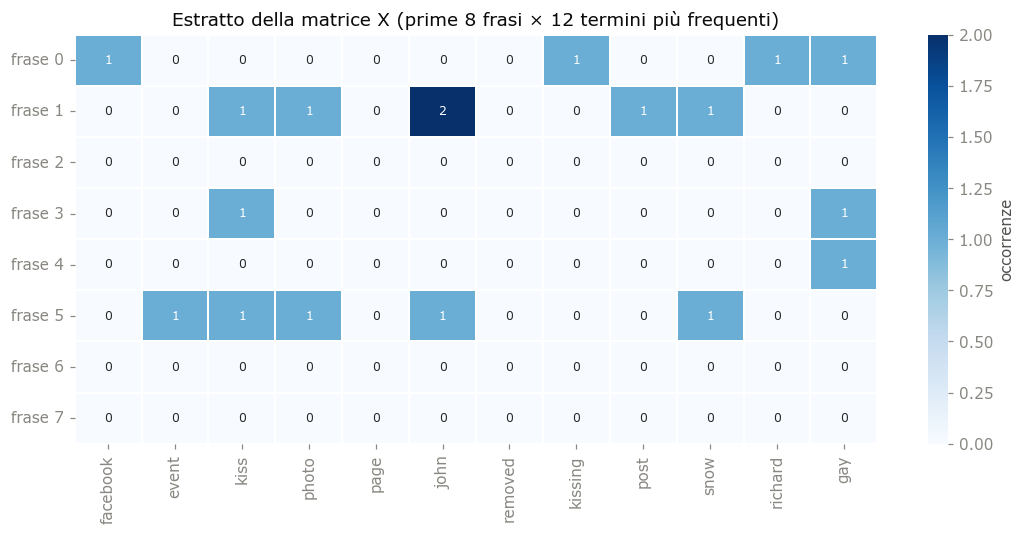

In [4]:
conteggi = CountVectorizer(stop_words='english')
X = conteggi.fit_transform(frasi)             # sparsa (N, V) di interi — la X di analizza_lda()
Xd = X.toarray()
vocabolario = conteggi.get_feature_names_out()
V = len(vocabolario)
print(f'Matrice X: {N} frasi × {V} termini | celle diverse da zero: {(Xd > 0).mean():.1%}  → matrice sparsa')
print(f'Occorrenze totali (token) dopo le stop-word: {int(Xd.sum())} | per frase: min {int(Xd.sum(1).min())}, '
      f'mediana {int(np.median(Xd.sum(1)))}, max {int(Xd.sum(1).max())}')
print(f'Valore massimo di una cella: {int(Xd.max())}  → quasi tutti i termini compaiono una volta sola in una frase')

# stessa struttura di TF-IDF: cambia solo il PESO delle celle non nulle (LSA, notebook 15)
A = TfidfVectorizer(stop_words='english').fit_transform(frasi)
assert A.shape == X.shape and (A > 0).nnz == X.nnz
print('✔ CountVectorizer e TfidfVectorizer riempiono le STESSE celle: cambia solo il peso (intero vs TF-IDF)')

top_termini = np.argsort(-Xd.sum(axis=0))[:12]
n_ant = min(8, N)
estratto = pd.DataFrame(Xd[:n_ant][:, top_termini], columns=[vocabolario[j] for j in top_termini],
                        index=[f'frase {i}' for i in range(n_ant)])
fig, ax = plt.subplots(figsize=(10, 0.42 * n_ant + 1.6))
sns.heatmap(estratto, annot=True, fmt='d', annot_kws={'size': 8}, cmap='Blues', vmin=0,
            linewidths=.3, linecolor='white', cbar_kws={'label': 'occorrenze'}, ax=ax)
ax.set_title(f'Estratto della matrice X (prime {n_ant} frasi × 12 termini più frequenti)')
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Ogni frase è un vettore lunghissimo (una componente per termine) e quasi tutto
zeri; le frasi sono corte, quindi ognuna contiene pochi token (sulla riga 50492: mediana 14 dopo le stop-word).
Questo è un dato da ricordare: per LDA una frase è un "documento" di **pochissime parole**, e con così poca
evidenza per documento il modello avrà poco su cui basarsi (lo si vedrà nella sezione 5).

## 4. Il modello e i temi: β
### Il processo generativo
LDA racconta come sarebbe "scritta" una frase. Per **ogni frase**:

1. si estrae una **miscela di temi** θ (K proporzioni ≥ 0 che sommano a 1) da una distribuzione di
   **Dirichlet** di parametro α;
2. per **ogni parola** della frase: si sceglie un tema `z` con probabilità θ, poi si sceglie la parola `w`
   tra quelle del tema, con probabilità **β**[z, w].

Ogni tema `t` è dunque una **distribuzione di probabilità sul vocabolario** (la riga β[t], ≥ 0, somma 1): le
sue parole più probabili ne danno il "significato". Anche β ha un priore di Dirichlet (parametro η). In
scikit-learn, per default, α = η = 1/K: un priore **sparso**, che preferisce frasi con *pochi* temi e temi
con *poche* parole.

Il **fitting** fa il percorso inverso: dai conteggi `X` stima β (topic → parole) e θ (frase → topic). Lo fa
con *inferenza variazionale* (una variante dell'algoritmo EM), non in forma chiusa: non c'è una formula, ma
un'iterazione che parte da valori casuali (`random_state`) e si ferma dopo al più `max_iter` = 10 passate (il
default di scikit-learn), in un **ottimo locale**.

`lda.components_` contiene i pesi non normalizzati λ del posteriore di β (pseudo-conteggi); normalizzando le righe
si ottiene β.

In [5]:
K = max(1, min(N_TOPICS, N))                     # come analizza_lda(): al più un tema per frase
lda = LatentDirichletAllocation(n_components=K, random_state=SEED)
theta = lda.fit_transform(X)                     # (N, K): θ, ogni riga è una distribuzione sui temi
lam = lda.components_                            # (K, V): λ, pseudo-conteggi
beta = lam / lam.sum(axis=1, keepdims=True)      # (K, V): β, ogni riga è una distribuzione sulle parole
alpha, eta = lda.doc_topic_prior_, lda.topic_word_prior_

print(f'LDA con K = {K} temi | priori: α = {alpha:.2f}, η = {eta:.2f} (default 1/K) | iterazioni EM: {lda.n_iter_} '
      f'(max_iter di default)')
print(f'θ {theta.shape} (frase × tema) | β {beta.shape} (tema × termine)')
assert np.allclose(theta.sum(axis=1), 1) and np.allclose(beta.sum(axis=1), 1) and (beta >= 0).all()
print('✔ ogni riga di θ somma a 1 (miscela di temi) e ogni riga di β somma a 1 (distribuzione sulle parole)')

# --- il processo generativo, "al contrario": scriviamo una frase finta con il modello adattato ---
rng = np.random.default_rng(0)
N_PAROLE_DEMO = 10
theta_demo = rng.dirichlet(np.full(K, alpha))                    # 1. miscela di temi della frase
z = rng.choice(K, size=N_PAROLE_DEMO, p=theta_demo)              # 2a. un tema per ogni parola
w = [vocabolario[rng.choice(V, p=beta[t])] for t in z]           # 2b. una parola dal tema scelto
print(f'\nFrase generata dal modello: θ = {np.round(theta_demo, 2)}')
print('  ' + ' '.join(f'{p}(T{t})' for p, t in zip(w, z)))

LDA con K = 5 temi | priori: α = 0.20, η = 0.20 (default 1/K) | iterazioni EM: 10 (max_iter di default)
θ (19, 5) (frase × tema) | β (5, 207) (tema × termine)
✔ ogni riga di θ somma a 1 (miscela di temi) e ogni riga di β somma a 1 (distribuzione sulle parole)

Frase generata dal modello: θ = [0.18 0.   0.6  0.14 0.08]
  administrators(T3) boyfriend(T0) played(T3) place(T0) picture(T2) gay(T0) wrong(T3) using(T2) protesting(T2) posting(T2)


**Cosa abbiamo visto.** La "frase" generata è un sacco di parole senza grammatica: LDA non sa nulla di ordine o
sintassi, solo di **quali parole stanno insieme**. In questa estrazione θ è sbilanciato su un tema e gli altri
pesano poco: è tipico del priore sparso (α = 0,2), che favorisce frasi con pochi temi dominanti.

### Le parole dei temi
Le parole con β più alta danno il significato di ogni tema (colore e titolo `T0…Tk` coerenti in tutte le figure).

T0 (massa λ = 59): taken, christian, boyfriend, 2008, episode, kisses, october, aired
T1 (massa λ = 111): just, event, paul, boing, hey, people, rights, men
T2 (massa λ = 181): facebook, event, photo, page, removed, snow, kissing, john
T3 (massa λ = 67): kiss, gay, promote, london, pub, protest, inconvenience, apologize
T4 (massa λ = 99): richard, kiss, post, john, photo, used, shetler, wall


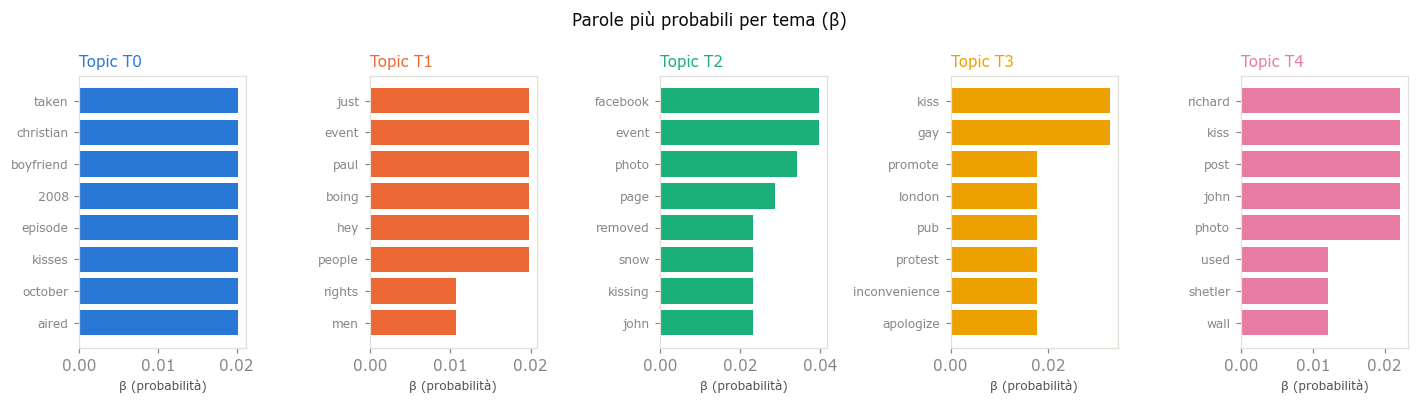

In [6]:
N_PAROLE_TOP = 8
COL_T = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
col_t = lambda t: COL_T[int(t) % len(COL_T)]

for t in range(K):
    parole = [vocabolario[j] for j in np.argsort(-beta[t])[:N_PAROLE_TOP]]
    print(f'T{t} (massa λ = {lam[t].sum():.0f}): {", ".join(parole)}')

fig, assi = plt.subplots(1, K, figsize=(2.5 * K + 0.5, 0.30 * N_PAROLE_TOP + 1.3))
assi = np.atleast_1d(assi)
for t, ax in enumerate(assi):
    idx = np.argsort(-beta[t])[:N_PAROLE_TOP][::-1]
    ax.barh(range(len(idx)), beta[t][idx], color=col_t(t))
    ax.set_yticks(range(len(idx))); ax.set_yticklabels([vocabolario[j] for j in idx], fontsize=8)
    ax.set_title(f'Topic T{t}', color=col_t(t), loc='left', fontsize=10)
    ax.set_xlabel('β (probabilità)', fontsize=8)
fig.suptitle('Parole più probabili per tema (β)', fontsize=11)
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Ogni tema è un piccolo gruppo di parole che **co-occorrono** nelle stesse frasi: qui
c'è, per esempio, un tema sulla pagina Facebook e sulla foto rimossa, uno su un episodio TV citato di passaggio,
uno sul bacio e sulla protesta a Londra. Due differenze con i "concetti" di LSA (notebook 15, sezione 4):

- le probabilità sono tutte **≥ 0** e sommano a 1, quindi un tema si legge direttamente (in LSA i carichi hanno segno arbitrario);
- i temi **non sono ortogonali**: la stessa parola (qui *event*, *kiss*, *photo*) può comparire in più temi.

⚠️ L'identità dei temi dipende dal seme: con un altro `random_state` gli stessi gruppi di parole possono
uscire con **numerazione diversa** (T2 al posto di T0) o fondersi/scindersi in modo diverso. Non c'è una "T0" stabile.

## 5. Le frasi come miscele di temi: θ
Fissati i temi (β), a ogni frase si assegna la sua miscela θ: l'**inferenza** di θ per una frase è un'iterazione
a due passi che si ripetono fino a convergenza:

1. dato θ della frase, per ogni *parola distinta* si calcola con quale probabilità è stata generata da ciascun
   tema (φ(w,k) ∝ exp(E[log θ_k]) · exp(E[log β_{k,w}]));
2. dati φ e i conteggi, si aggiorna θ: **γₖ = α + Σ_w n_w · φ(w,k)** (il parametro del Dirichlet del posteriore, che
   è il "α più i conteggi attribuiti al tema").

Le attese dei logaritmi usano la funzione **digamma** ψ. Scikit-learn fa esattamente questo in `transform`;
qui la riscriviamo per una frase alla volta e verifichiamo che dia lo **stesso** θ.

iterazioni per frase: min 3, max 9 | scarto massimo da lda.transform: 9.6e-13
✔ θ calcolata a mano (γ = α + Σ n·φ, con le attese via digamma) coincide con quella di scikit-learn


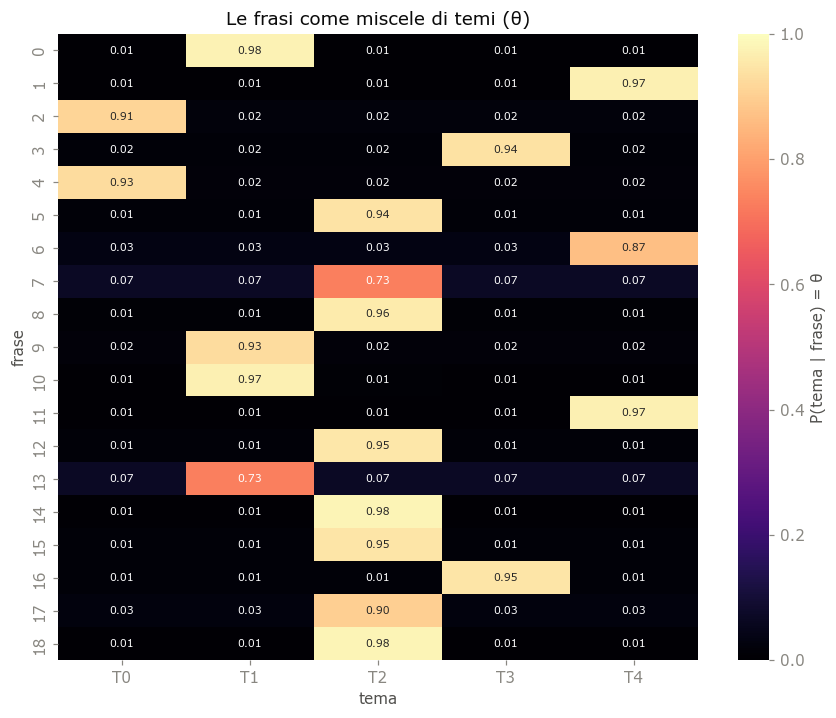

θ massimo per frase: min 0.73, mediana 0.95 | frasi con θ massimo ≥ 0,9: 15 su 19


In [7]:
def theta_a_mano(conteggi_frase, lam, alpha, tol=1e-3, max_iter=100):
    """E-step variazionale per UNA frase: restituisce (θ normalizzato, iterazioni usate)."""
    ids = np.nonzero(conteggi_frase)[0]                                  # solo le parole presenti nella frase
    cnt = conteggi_frase[ids].astype(float)
    exp_beta = np.exp(digamma(lam[:, ids]) - digamma(lam.sum(axis=1, keepdims=True)))   # exp E[log β]  (K, parole)
    gamma = np.ones(lam.shape[0])                                        # parametro del Dirichlet di θ
    for it in range(1, max_iter + 1):
        exp_theta = np.exp(digamma(gamma) - digamma(gamma.sum()))        # exp E[log θ]
        norma_phi = exp_theta @ exp_beta + np.finfo(float).eps           # normalizzazione di φ per ogni parola
        nuovo = exp_theta * ((cnt / norma_phi) @ exp_beta.T) + alpha     # γ = α + Σ_w n_w φ_wk
        cambio = np.abs(nuovo - gamma).mean()
        gamma = nuovo
        if cambio < tol:                                                 # soglia di convergenza di sklearn
            break
    return gamma / gamma.sum(), it

risultati = [theta_a_mano(Xd[i], lam, alpha) for i in range(N)]
theta_mano = np.array([r[0] for r in risultati])
iterazioni = [r[1] for r in risultati]
scarto = np.abs(theta_mano - theta).max()
print(f'iterazioni per frase: min {min(iterazioni)}, max {max(iterazioni)} | scarto massimo da lda.transform: {scarto:.1e}')
assert np.allclose(theta_mano, theta, atol=1e-9)
print('✔ θ calcolata a mano (γ = α + Σ n·φ, con le attese via digamma) coincide con quella di scikit-learn')

fig, ax = plt.subplots(figsize=(1.1 * K + 2.5, 0.27 * N + 1.5))
sns.heatmap(theta, cmap='magma', vmin=0, vmax=1, annot=(N <= 25), fmt='.2f', annot_kws={'size': 7},
            xticklabels=[f'T{t}' for t in range(K)], yticklabels=range(N),
            cbar_kws={'label': 'P(tema | frase) = θ'}, ax=ax)
ax.set_xlabel('tema'); ax.set_ylabel('frase')
ax.set_title('Le frasi come miscele di temi (θ)')
plt.tight_layout(); plt.show()

max_theta = theta.max(axis=1)
print(f'θ massimo per frase: min {max_theta.min():.2f}, mediana {np.median(max_theta):.2f} | '
      f'frasi con θ massimo ≥ 0,9: {(max_theta >= 0.9).sum()} su {N}')

**Cosa abbiamo visto.** Pur essendo "morbida" in teoria (una miscela), nella pratica θ è quasi **dura**: sulla
riga 50492 ogni frase ha una cella accesa e le altre quasi spente (il θ massimo non scende sotto 0,73 e arriva a
0,9 o più in 15 frasi su 19). Con frasi di pochi token e un priore sparso (α = 0,2) il modello decide quasi sempre che
*ogni frase parla di un solo tema*: LDA si comporta qui come un **clustering di frasi**, con i temi come cluster
(un'idea più vicina al notebook 16 che a LSA).

Questa quasi-durezza non è uniforme. Mettiamo in relazione **quanto è netta la frase** (il suo θ massimo) con la
sua **lunghezza**.

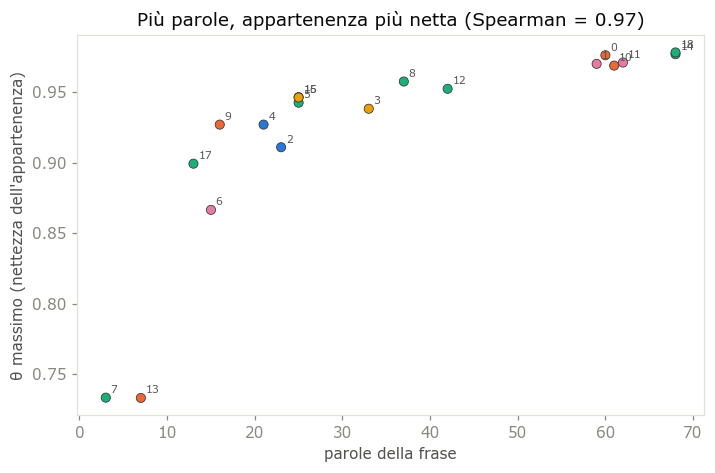

correlazione di Spearman tra lunghezza della frase e θ massimo: 0.97
la frase più corta (3 parole, indice 7) ha θ massimo 0.73; le più lunghe (68 parole) 0.98


In [8]:
spearman = pd.Series(max_theta).corr(pd.Series(parole_frase), method='spearman')
fig, ax = plt.subplots(figsize=(6.6, 4.4))
ax.scatter(parole_frase, max_theta, s=36, c=[col_t(t) for t in theta.argmax(axis=1)], edgecolors='#333', linewidths=.5)
for i in range(N):
    ax.annotate(str(i), (parole_frase[i], max_theta[i]), xytext=(3, 3), textcoords='offset points', fontsize=7, color='#555')
ax.set_xlabel('parole della frase'); ax.set_ylabel('θ massimo (nettezza dell\'appartenenza)')
ax.set_title(f'Più parole, appartenenza più netta (Spearman = {spearman:.2f})')
plt.tight_layout(); plt.show()
print(f'correlazione di Spearman tra lunghezza della frase e θ massimo: {spearman:.2f}')
print(f'la frase più corta ({int(parole_frase.min())} parole, indice {int(parole_frase.argmin())}) ha θ massimo '
      f'{max_theta[parole_frase.argmin()]:.2f}; le più lunghe ({int(parole_frase.max())} parole) {max_theta[parole_frase.argmax()]:.2f}')

**Cosa abbiamo visto.** Più una frase è lunga, più il suo θ massimo è vicino a 1: sulle frasi **corte** la
spiegazione è semplice, perché γ = α + conteggi attribuiti ai temi e con pochi conteggi il priore (che spalma una
massa fissa di α·K = 1 su tutti i temi) pesa molto e tiene θ più incerto. Ma sulle frasi **lunghe** ci si aspetterebbe
l'opposto: più parole dovrebbero toccare più temi, quindi una miscela più diluita. Perché non succede?

### Una verifica: la frase è già nell'addestramento
C'è un sospetto. I temi sono stimati **su queste stesse 19 frasi**, con 207 parole di cui molte compaiono una sola
volta: un tema finisce per essere "le parole delle frasi che gli sono capitate". Se poi si chiede a una di quelle
frasi a quale tema appartiene, la risposta è circolare. Una frase lunga porta più parole e plasma di più il proprio
tema, quindi risulta più netta.

Lo verifichiamo togliendo **una frase alla volta** dall'addestramento: si adatta LDA sulle altre 18 e poi si
calcola θ della frase esclusa. Se il sospetto è giusto, le frasi lunghe dovrebbero diventare le più diluite. In
parallelo si prova a variare α, per separare l'effetto del priore.

(a) θ massimo con la frase DENTRO l'addestramento (come nel benchmark) o FUORI (leave-one-out):
    mediana: dentro 0.95 | fuori 0.58
    frasi con almeno 20 token (6): dentro 0.97 | fuori 0.42
    correlazione di Spearman con la lunghezza (token): dentro +1.00 | fuori -0.61


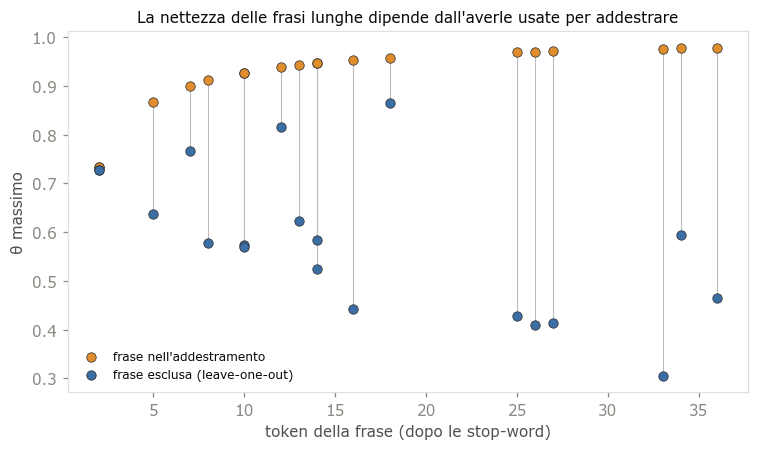


(b) Effetto del priore α (frasi nell'addestramento):
    α = 0.2: θ massimo mediano 0.95, minimo 0.73, Spearman con la lunghezza +1.00
    α = 0.5: θ massimo mediano 0.86, minimo 0.55, Spearman con la lunghezza +1.00
    α = 1.0: θ massimo mediano 0.74, minimo 0.42, Spearman con la lunghezza +0.93


In [9]:
token_frase = np.asarray(X.sum(axis=1)).ravel()            # token dopo le stop-word (è ciò che LDA vede)

# (a) leave-one-out: θ di una frase stimato da un modello che NON l'ha vista
theta_fuori = np.zeros(N)
for i in range(N):
    resto = [j for j in range(N) if j != i]
    modello_i = LatentDirichletAllocation(n_components=K, random_state=SEED).fit(X[resto])
    theta_fuori[i] = modello_i.transform(X[i]).max()

lunghe = token_frase >= 20
sp_dentro = pd.Series(max_theta).corr(pd.Series(token_frase), method='spearman')
sp_fuori = pd.Series(theta_fuori).corr(pd.Series(token_frase), method='spearman')
print('(a) θ massimo con la frase DENTRO l\'addestramento (come nel benchmark) o FUORI (leave-one-out):')
print(f'    mediana: dentro {np.median(max_theta):.2f} | fuori {np.median(theta_fuori):.2f}')
print(f'    frasi con almeno 20 token ({int(lunghe.sum())}): dentro {np.median(max_theta[lunghe]):.2f} | fuori {np.median(theta_fuori[lunghe]):.2f}')
print(f'    correlazione di Spearman con la lunghezza (token): dentro {sp_dentro:+.2f} | fuori {sp_fuori:+.2f}')

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(token_frase, max_theta, s=38, color='#e08e2b', edgecolors='#333', linewidths=.5, label='frase nell\'addestramento')
ax.scatter(token_frase, theta_fuori, s=38, color='#3b6ea5', edgecolors='#333', linewidths=.5, label='frase esclusa (leave-one-out)')
for i in range(N):
    ax.plot([token_frase[i]] * 2, [theta_fuori[i], max_theta[i]], color='#bbb', lw=.7, zorder=0)
ax.set_xlabel('token della frase (dopo le stop-word)'); ax.set_ylabel('θ massimo')
ax.set_title('La nettezza delle frasi lunghe dipende dall\'averle usate per addestrare', fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.tight_layout(); plt.show()

# (b) il priore: α più alto diluisce θ, ma non spiega da solo la relazione con la lunghezza
print('\n(b) Effetto del priore α (frasi nell\'addestramento):')
for a_ in (0.2, 0.5, 1.0):
    th_a = LatentDirichletAllocation(n_components=K, doc_topic_prior=a_, random_state=SEED).fit_transform(X)
    print(f'    α = {a_}: θ massimo mediano {np.median(th_a.max(axis=1)):.2f}, minimo {th_a.max(axis=1).min():.2f}, '
          f'Spearman con la lunghezza {pd.Series(th_a.max(axis=1)).corr(pd.Series(token_frase), method="spearman"):+.2f}')

**Cosa abbiamo visto.** Il sospetto è confermato. Con la frase **esclusa** dall'addestramento il θ massimo
mediano scende da 0,95 a 0,58, e per le frasi lunghe (≥ 20 token) da 0,97 a 0,42; la correlazione con la
lunghezza **cambia segno** (da +1,00 a −0,61): fuori dall'addestramento le frasi lunghe sono le più diluite,
come ci si aspetta. La nettezza delle frasi lunghe che vedevamo prima era quindi in buona parte un **effetto
circolare**: il tema era fatto di quelle stesse parole.

Contano anche altri due meccanismi, più piccoli. Il priore (parte b): con α più alto θ si diluisce, ma la
correlazione con la lunghezza resta alta anche con α = 1, quindi il priore spiega perché le frasi *corte* siano
meno nette, non perché le lunghe lo siano così tanto. E l'aggiornamento di γ premia chi è già in vantaggio
(l'attesa exp(ψ(γ)) penalizza molto i temi con pochi conteggi): con più parole il tema in testa prende il
largo e gli altri si spengono.

⚠️ Conseguenza per il metodo: il benchmark calcola θ sulle frasi usate per l'addestramento, quindi il criterio
"θ più alto dentro il tema" privilegia le frasi lunghe in parte per questa circolarità, non perché siano davvero
più monotematiche. Il test è fatto su una sola riga di 19 frasi.

### Cosa "predice" il modello per una frase
Moltiplicando θ per β si ottiene la distribuzione di probabilità sulle parole attesa per ogni frase:
**P(w | frase) = Σₖ θ(frase,k) · β(k,w)**. È l'analogo, per LDA, della ricostruzione `A ≈ U·Σ·Vᵀ` di LSA.
Guardiamola per la frase più lunga: le parole che il modello ritiene più probabili non sono per forza quelle presenti.

In [10]:
P_parole = theta @ beta                                  # (N, V): P(w | frase)
assert np.allclose(P_parole.sum(axis=1), 1)
i_demo = int(np.argmax(parole_frase))
top_p = np.argsort(-P_parole[i_demo])[:10]
display(pd.DataFrame({'parola': [vocabolario[j] for j in top_p],
                      'P(w | frase)': P_parole[i_demo][top_p].round(3),
                      'occorrenze nella frase': Xd[i_demo][top_p]}).set_index('parola'))
assenti = int((Xd[i_demo][top_p] == 0).sum())
print(f'Frase {i_demo} ({parole_frase[i_demo]} parole): {assenti} delle 10 parole più probabili secondo il modello NON compaiono nella frase')

,P(w | frase),occorrenze nella frase
parola,,
facebook,0.039,1
event,0.039,0
photo,0.034,1
page,0.028,2
kiss,0.023,1
john,0.023,1
removed,0.023,1
snow,0.023,1
kissing,0.023,2


Frase 14 (68 parole): 2 delle 10 parole più probabili secondo il modello NON compaiono nella frase


**Cosa abbiamo visto.** Il modello assegna probabilità anche a parole **assenti** dalla frase, ma tipiche dei
suoi temi: è la versione probabilistica della "sinonimia" di LSA (notebook 15, sezione 6) — le parole che
co-occorrono con quelle della frase "entrano" nella sua rappresentazione. Su ~19 frasi l'effetto è limitato, perché
le co-occorrenze sono poche.

## 6. Allocazione proporzionale e selezione per tema
Ora che ogni frase ha una miscela θ, la selezione ragiona per **temi**:

1. **Peso del tema** = `Σ_frasi θ[:, t]` (somma della colonna): "quante frasi vale" quel tema. Con una θ quasi
   dura equivale grosso modo al numero di frasi che lo hanno come tema dominante.
2. **Quote**: le `N_SENTENCES` frasi si ripartiscono in proporzione al peso, `esatta = N_SENTENCES · peso / Σ peso`.
   Le quote devono essere intere e sommare esattamente a `N_SENTENCES`: si prende la **parte intera** di ciascuna
   e le unità mancanti (il *residuo*) vanno ai temi con la **parte frazionaria più alta**.
3. **Dentro ogni tema**: si scorrono le frasi per θ decrescente e si prendono le prime `quota`, **saltando** quelle
   già scelte da un tema precedente.
4. Se i salti impediscono di arrivare a `N_SENTENCES`, si **completa** con le frasi che hanno il θ massimo più alto.

Il codice qui sotto lo fa passo per passo, conservando la storia di ogni scelta.

In [11]:
def quote_a_mano(peso, n):
    """Parte intera + residuo ai temi con parte frazionaria più alta (esatte, base, frazione, quote)."""
    esatte = n * peso / peso.sum()
    base = np.floor(esatte).astype(int)
    frazione = esatte - base
    residuo = int(n - base.sum())
    extra = np.zeros_like(base)
    extra[np.argsort(-frazione)[:residuo]] = 1
    return esatte, base, frazione, base + extra

def seleziona_per_tema(theta, quote, n_sentences):
    """Per ogni tema le frasi a θ decrescente, saltando le già scelte; poi eventuale completamento."""
    scelti, gia, storia = [], set(), []
    for t in range(theta.shape[1]):
        presi = 0
        for i in np.argsort(-theta[:, t]):
            if presi >= quote[t]:
                break
            i = int(i)
            if i in gia:
                storia.append({'tema': t, 'frase': i, 'esito': 'saltata (già scelta)'})
                continue
            scelti.append(i); gia.add(i); presi += 1
            storia.append({'tema': t, 'frase': i, 'esito': 'scelta'})
    obiettivo = min(n_sentences, theta.shape[0])
    completate = []
    if len(scelti) < obiettivo:
        for i in np.argsort(-theta.max(axis=1)):
            i = int(i)
            if i not in gia:
                scelti.append(i); gia.add(i); completate.append(i)
            if len(scelti) >= obiettivo:
                break
    return scelti, storia, completate

peso = theta.sum(axis=0)
esatte, base, frazione, quote = quote_a_mano(peso, N_SENTENCES)
assert quote.sum() == N_SENTENCES
dominante = theta.argmax(axis=1)
display(pd.DataFrame({'peso Σθ': peso.round(2), 'frasi con questo tema dominante': np.bincount(dominante, minlength=K),
                      f'quota esatta ({N_SENTENCES}·peso/Σ)': esatte.round(2), 'parte intera': base,
                      'parte frazionaria': frazione.round(2), 'quota finale': quote},
                     index=[f'T{t}' for t in range(K)]))
print(f'residuo da distribuire: {N_SENTENCES - base.sum()} → va ai temi con la parte frazionaria più alta | '
      f'quote = {[int(q) for q in quote]} (somma {int(quote.sum())} = N_SENTENCES)')

scelti_mano, storia, completate = seleziona_per_tema(theta, quote, N_SENTENCES)
righe = []
for t in range(K):
    prese = [h['frase'] for h in storia if h['tema'] == t and h['esito'] == 'scelta']
    saltate = [h['frase'] for h in storia if h['tema'] == t and h['esito'] != 'scelta']
    righe.append({'tema': f'T{t}', 'quota': int(quote[t]), 'frasi scelte': prese,
                  'θ': [round(float(theta[i, t]), 2) for i in prese], 'saltate': saltate,
                  'parole': [int(parole_frase[i]) for i in prese]})
display(pd.DataFrame(righe).set_index('tema'))
print(f'saltate perché già scelte da un altro tema: {sum(h["esito"] != "scelta" for h in storia)} | '
      f'frasi aggiunte dal completamento: {completate if completate else "nessuna"}')

,peso Σθ,frasi con questo tema dominante,quota esatta (11·peso/Σ),parte intera,parte frazionaria,quota finale
T0,2.17,2,1.25,1,0.25,1
T1,3.88,4,2.24,2,0.24,2
T2,7.60,8,4.40,4,0.40,5
T3,2.22,2,1.29,1,0.29,1
T4,3.13,3,1.81,1,0.81,2


residuo da distribuire: 2 → va ai temi con la parte frazionaria più alta | quote = [1, 2, 5, 1, 2] (somma 11 = N_SENTENCES)


,quota,frasi scelte,θ,saltate,parole
tema,,,,,
T0,1,[4],[0.93],[],[21]
T1,2,"[0, 10]","[0.98, 0.97]",[],"[60, 61]"
T2,5,"[18, 14, 8, 12, 15]","[0.98, 0.98, 0.96, 0.95, 0.95]",[],"[68, 68, 37, 42, 25]"
T3,1,[16],[0.95],[],[25]
T4,2,"[11, 1]","[0.97, 0.97]",[],"[62, 59]"


saltate perché già scelte da un altro tema: 0 | frasi aggiunte dal completamento: nessuna


**Leggere le tabelle.** Il tema più pesante riceve più frasi, ma ogni tema con peso apprezzabile ne riceve almeno
una: è la **copertura**. I salti e il completamento servono solo in casi limite — con una θ quasi dura una
frase è quasi sempre la migliore *per un solo* tema, quindi i conflitti sono rari.

Verifichiamo ora che questa versione **coincida con l'implementazione del benchmark**. Qui sotto `segmenta`,
`alloca_quote`, `analizza_lda`, `seleziona_per_quote_parole` e `genera` sono copiate **identiche** dal notebook 17:
se un giorno le due divergessero, queste `assert` si romperebbero.

In [12]:
# --- copia fedele del codice di produzione (notebooks/17_lda.ipynb) ---------------------------------
def segmenta(documento):
    s = psr.summarization(documento, stop_words=STOP_WORDS)
    return [f.strip() for f in getattr(s, 'original', []) if f and f.strip()]


def alloca_quote(peso_topic, n_sentences):
    peso = np.asarray(peso_topic, dtype=float)
    tot = peso.sum()
    if tot <= 0:                                   # pesi degeneri: riparto uniforme
        quote = np.zeros(len(peso), dtype=int)
        for i in range(n_sentences):
            quote[i % len(peso)] += 1
        return quote
    esatte = n_sentences * peso / tot
    quote = np.floor(esatte).astype(int)
    residuo = int(n_sentences - quote.sum())
    ordine = np.argsort(-(esatte - quote))         # parte frazionaria decrescente
    for i in range(residuo):
        quote[ordine[i % len(ordine)]] += 1
    return quote


def analizza_lda(frasi, k=None, n_sentences=None):
    k = N_TOPICS if k is None else k
    n_sentences = N_SENTENCES if n_sentences is None else n_sentences
    k = max(1, min(k, len(frasi)))
    conteggi = CountVectorizer(stop_words='english')
    X = conteggi.fit_transform(frasi)              # (n_frasi, vocab); ValueError se vuoto
    lda = LatentDirichletAllocation(n_components=k, random_state=SEED)
    theta = lda.fit_transform(X)                   # (n_frasi, k), riga ~ distribuzione sui topic
    peso_topic = theta.sum(axis=0)                 # importanza di ogni topic nel cluster
    quote = alloca_quote(peso_topic, n_sentences)

    scelti, gia = [], set()
    for t in range(k):
        presi = 0
        for i in np.argsort(-theta[:, t]):         # frasi per appartenenza decrescente al topic t
            if presi >= quote[t]:
                break
            i = int(i)
            if i in gia:
                continue
            scelti.append(i)
            gia.add(i)
            presi += 1
    # se i duplicati hanno impedito di raggiungere il budget, completo con le frasi piu' salienti
    obiettivo = min(n_sentences, len(frasi))
    if len(scelti) < obiettivo:
        for i in np.argsort(-theta.max(axis=1)):
            i = int(i)
            if i not in gia:
                scelti.append(i)
                gia.add(i)
            if len(scelti) >= obiettivo:
                break
    return {'theta': theta, 'peso_topic': peso_topic, 'quote': quote, 'scelti': scelti,
            'vocab': conteggi.get_feature_names_out(), 'componenti': lda.components_, 'k': k}


def seleziona_per_quote_parole(frasi, theta, budget_parole):
    peso = theta.sum(axis=0)
    quote = (budget_parole * peso / peso.sum() if peso.sum() > 0
             else np.full(len(peso), budget_parole / len(peso)))
    scelti, gia = [], set()
    for t in np.argsort(-peso):
        totale = 0
        for i in np.argsort(-theta[:, t]):
            i = int(i)
            if i in gia:
                continue
            n = len(frasi[i].split())
            if totale + n <= quote[t]:
                scelti.append(i)
                gia.add(i)
                totale += n
                continue
            if quote[t] - totale > n / 2:
                scelti.append(i)
                gia.add(i)
            break
    parole_scelte = sum(len(frasi[i].split()) for i in scelti)
    if parole_scelte < 0.8 * budget_parole:
        residuo = [int(i) for i in np.argsort(-theta.max(axis=1)) if int(i) not in gia]
        if residuo:
            scelti += su.seleziona_per_budget(frasi, residuo, budget_parole - parole_scelte)
    return scelti


def genera(documento, budget=None):
    frasi = segmenta(documento)
    if budget is None and len(frasi) <= N_SENTENCES:
        return ' '.join(frasi)
    try:
        if budget is None:
            indici = analizza_lda(frasi)['scelti']
        else:
            indici = seleziona_per_quote_parole(frasi, analizza_lda(frasi)['theta'], budget)
    except ValueError:            # vocabolario CountVectorizer vuoto su testi minimi
        indici = (range(N_SENTENCES) if budget is None
                  else su.seleziona_per_budget(frasi, range(len(frasi)), budget))
    return ' '.join(frasi[i] for i in sorted(indici))
# ---------------------------------------------------------------------------------------------------

assert segmenta(documento) == frasi
art = analizza_lda(frasi)
assert np.allclose(art['theta'], theta) and art['k'] == K
assert [int(q) for q in art['quote']] == [int(q) for q in quote] == [int(q) for q in alloca_quote(peso, N_SENTENCES)]
assert art['scelti'] == scelti_mano, 'la selezione scritta a mano deve coincidere con il benchmark'
print(f'✔ Segmentazione, θ, quote {[int(q) for q in quote]} e frasi scelte {art["scelti"]} coincidono con il notebook 17')

✔ Segmentazione, θ, quote [1, 2, 5, 1, 2] e frasi scelte [4, 0, 10, 18, 14, 8, 12, 15, 16, 11, 1] coincidono con il notebook 17


### La mappa tematica e la copertura
La prima figura mostra peso e quota di ogni tema. La **mappa tematica** dispone le frasi in ordine di documento
sull'asse x e il loro **tema dominante** sull'asse y; le frasi cerchiate sono quelle selezionate. L'obiettivo è **toccare
tutti i temi**. La stampa finale confronta la copertura con una baseline ingenua: le `N_SENTENCES` frasi con il θ
massimo più alto, senza quote.

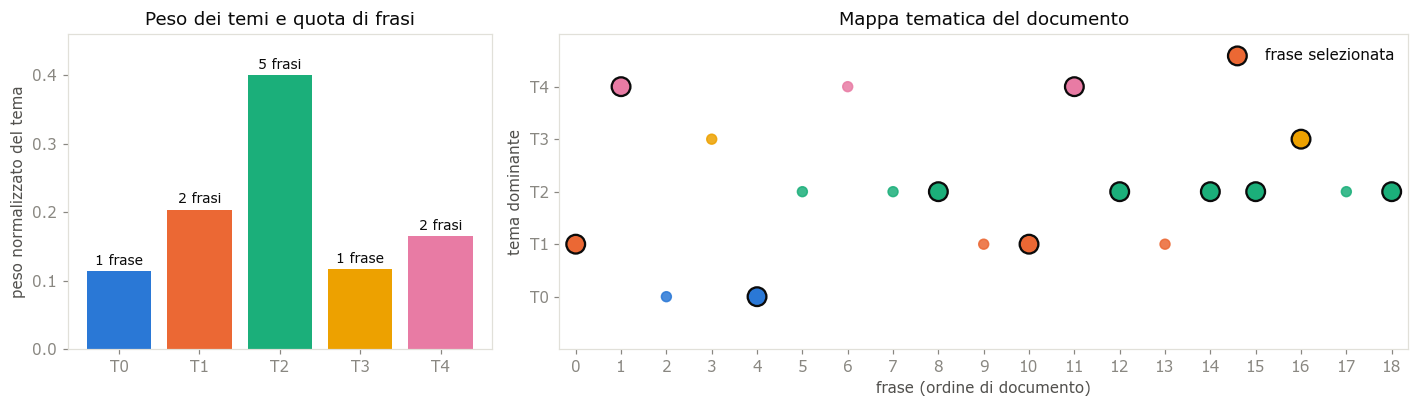

Copertura tematica della selezione:
  allocazione proporzionale        : temi [0, 1, 2, 3, 4] (5/5) | 528 parole
  baseline top-11 per θ massimo  : temi [1, 2, 3, 4] (4/5) | 532 parole

Frasi selezionate (ordine di documento), con tema dominante e lunghezza:
  [ 0] (T1, 60 parole) UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesperson f
  [ 1] (T4, 59 parole) First of all, with regards to the picture: 
 
 The photo which was used to illustrate my first post about the 
  [ 4] (T0, 21 parole) However, since this episode aired (October 2008) Christian now has a boyfriend and a few more gay kisses have 
  [ 8] (T2, 37 parole) Secondly, the removal of the Facebook John Snow Kiss-In event: 
 
 It turns out that the Facebook event for th
  [10] (T1, 61 parole) Before it goes too far, I just want people to know that FB have NOT removed the kiss-in event page; it’s still
  [11] (T4, 62 parole) Now if Facebook will only reply to Richard’s que

In [13]:
scelti = art['scelti']
sel = np.zeros(N, dtype=bool); sel[scelti] = True

fig, assi = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={'width_ratios': [1, 2]})
peso_norm = peso / peso.sum()
assi[0].bar(range(K), peso_norm, color=[col_t(t) for t in range(K)])
for t in range(K):
    assi[0].annotate(f'{int(quote[t])} ' + ('frase' if quote[t] == 1 else 'frasi'), (t, peso_norm[t]), xytext=(0, 4), textcoords='offset points', ha='center', fontsize=9)
assi[0].set_xticks(range(K)); assi[0].set_xticklabels([f'T{t}' for t in range(K)])
assi[0].set_ylabel('peso normalizzato del tema'); assi[0].set_title('Peso dei temi e quota di frasi'); assi[0].margins(y=.15)

assi[1].scatter(np.where(~sel)[0], dominante[~sel], s=42, c=[col_t(t) for t in dominante[~sel]], alpha=.85, zorder=2)
assi[1].scatter(np.where(sel)[0], dominante[sel], s=150, c=[col_t(t) for t in dominante[sel]], edgecolors='#0b0b0b',
                linewidths=1.5, zorder=3, label='frase selezionata')
assi[1].set_yticks(range(K)); assi[1].set_yticklabels([f'T{t}' for t in range(K)])
assi[1].set_xticks(range(N)); assi[1].set_xlabel('frase (ordine di documento)'); assi[1].set_ylabel('tema dominante')
assi[1].set_title('Mappa tematica del documento'); assi[1].legend(frameon=False, loc='upper right'); assi[1].margins(x=.02, y=.25)
plt.tight_layout(); plt.show()

propor = sorted(set(int(dominante[i]) for i in scelti))
naive_idx = [int(i) for i in np.argsort(-max_theta)[:N_SENTENCES]]
naive = sorted(set(int(dominante[i]) for i in naive_idx))
print('Copertura tematica della selezione:')
print(f'  allocazione proporzionale        : temi {propor} ({len(propor)}/{K}) | {int(parole_frase[scelti].sum())} parole')
print(f'  baseline top-{N_SENTENCES} per θ massimo  : temi {naive} ({len(naive)}/{K}) | {int(parole_frase[naive_idx].sum())} parole')
print(f'\nFrasi selezionate (ordine di documento), con tema dominante e lunghezza:')
for i in sorted(scelti):
    print(f'  [{i:>2}] (T{int(dominante[i])}, {parole_frase[i]:>2} parole) {frasi[i][:110]}')
print(f'\nNon selezionate: {[(i, int(parole_frase[i])) for i in range(N) if not sel[i]]}  (indice, parole)')

**Cosa abbiamo visto.** L'allocazione proporzionale tocca **tutti** i temi; la baseline ingenua, che prende le 11
frasi con θ più alto senza quote, ne lascia scoperto uno: è il vantaggio della copertura. L'altro lato della
medaglia sta nell'ultima riga: le frasi **non selezionate** sono corte (la più lunga ne ha 33 parole), mentre 7 delle
11 selezionate ne hanno più di 40. Il criterio "θ più alto dentro il tema" è la sezione 5 in azione: premia le
frasi lunghe, perché sono quelle di cui il modello è più sicuro (in parte per circolarità, sezione 5). Sulla riga 50492 le 11 frasi scelte contano più di
500 parole, circa il doppio di quanto sceglie LSA per le sue 11 frasi sulla stessa riga (~270-310, notebook 15);
nel benchmark è lo stesso fenomeno (~477 parole per riassunto contro ~250).

## 7. (Intermezzo) Quanto è stabile? `N_TOPICS` e `random_state`
LDA ha due manopole che LSA non ha, o ha in forma diversa: il **numero di temi** e il **seme casuale**. Il
benchmark le fissa (5 temi, seme 42) senza ottimizzarle; qui le variamo sulla stessa riga. Per farlo usiamo le
funzioni a mano della sezione 6, con `random_state` e `N_TOPICS` come parametri (e verifichiamo che per i valori
del benchmark diano la selezione di produzione).

✔ pipeline_lda(N_TOPICS, SEED) coincide con analizza_lda() del benchmark


(a) Effetto del numero di temi (stesso seme):


,quote,temi con quota > 0,temi dominanti coperti,parole del set,frasi in comune con N_TOPICS = 5
N_TOPICS,,,,,
2,4 7,2,2/2,532,10
3,1 4 6,3,3/3,527,9
5,1 2 5 1 2,5,5/5,528,11
8,1 2 3 1 1 1 1 1,8,8/8,536,10
11,0 1 2 0 1 1 1 2 1 1 1,9,9/9,530,9
15,0 0 1 1 0 1 1 1 2 0 2 1 0 1 0,9,9/10,480,9
19,0 0 1 1 0 1 1 0 0 0 2 1 0 1 0 0 1 0 2,9,9/9,519,9



(b) Effetto del seme (10 semi, N_TOPICS = 5): somiglianza (Jaccard) tra i set di frasi scelti
  rispetto al seme 42 del benchmark: media 0.71, minimo 0.57
  tra tutte le coppie di semi             : media 0.64, minimo 0.47
  frasi scelte con TUTTI i semi: [0, 1, 11, 14, 18] (5 su 11)


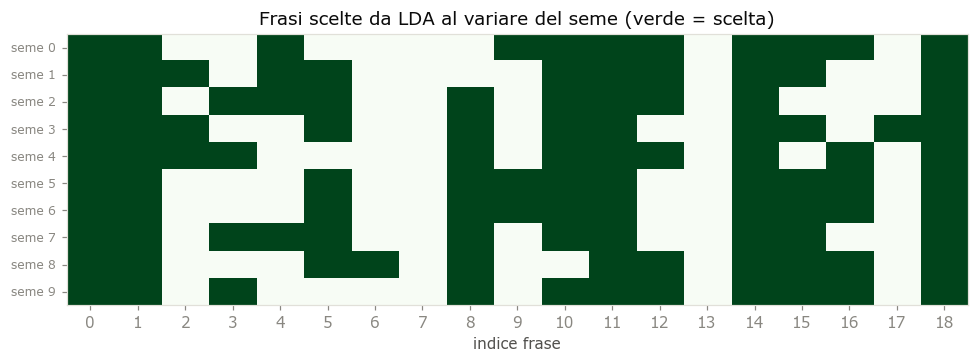

In [14]:
def pipeline_lda(frasi_, k, seme, n_sentences=N_SENTENCES):
    X_ = CountVectorizer(stop_words='english').fit_transform(frasi_)
    k = max(1, min(k, len(frasi_)))
    th = LatentDirichletAllocation(n_components=k, random_state=seme).fit_transform(X_)
    q = alloca_quote(th.sum(axis=0), n_sentences)
    sc, _, _ = seleziona_per_tema(th, q, n_sentences)
    return th, q, sc

assert pipeline_lda(frasi, N_TOPICS, SEED)[2] == analizza_lda(frasi)['scelti']
print('✔ pipeline_lda(N_TOPICS, SEED) coincide con analizza_lda() del benchmark')

# --- (a) effetto di N_TOPICS ---
righe = []
sel_base = set(analizza_lda(frasi)['scelti'])
for k_ in sorted({2, 3, 5, 8, 11, 15, N}):
    th_, q_, sc_ = pipeline_lda(frasi, k_, SEED)
    dom_ = th_.argmax(axis=1)
    righe.append({'N_TOPICS': min(k_, N), 'quote': ' '.join(str(int(x)) for x in q_),
                  'temi con quota > 0': int((q_ > 0).sum()),
                  'temi dominanti coperti': f'{len(set(dom_[sc_]))}/{len(set(dom_))}',
                  'parole del set': int(parole_frase[sc_].sum()),
                  f'frasi in comune con N_TOPICS = {N_TOPICS}': len(set(sc_) & sel_base)})
print('(a) Effetto del numero di temi (stesso seme):')
display(pd.DataFrame(righe).set_index('N_TOPICS'))

# --- (b) effetto del seme ---
SEMI = list(range(10))
sel_seme = {s_: set(pipeline_lda(frasi, N_TOPICS, s_)[2]) for s_ in SEMI}
jacc = lambda a, b: len(a & b) / len(a | b)
vs_benchmark = [jacc(sel_seme[s_], sel_base) for s_ in SEMI if s_ != SEED]
coppie = [jacc(sel_seme[a], sel_seme[b]) for a in SEMI for b in SEMI if a < b]
sempre = set.intersection(*sel_seme.values())
print(f'\n(b) Effetto del seme ({len(SEMI)} semi, N_TOPICS = {N_TOPICS}): somiglianza (Jaccard) tra i set di frasi scelti')
print(f'  rispetto al seme {SEED} del benchmark: media {np.mean(vs_benchmark):.2f}, minimo {np.min(vs_benchmark):.2f}')
print(f'  tra tutte le coppie di semi             : media {np.mean(coppie):.2f}, minimo {np.min(coppie):.2f}')
print(f'  frasi scelte con TUTTI i semi: {sorted(sempre)} ({len(sempre)} su {N_SENTENCES})')

fig, ax = plt.subplots(figsize=(9, 3.4))
M = np.zeros((len(SEMI), N))
for r_, s_ in enumerate(SEMI):
    M[r_, list(sel_seme[s_])] = 1.0
ax.imshow(M, cmap='Greens', vmin=0, vmax=1, aspect='auto')
ax.set_yticks(range(len(SEMI))); ax.set_yticklabels([f'seme {s_}' for s_ in SEMI], fontsize=8)
ax.set_xticks(range(N)); ax.set_xlabel('indice frase'); ax.set_title('Frasi scelte da LDA al variare del seme (verde = scelta)')
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.**

- **`N_TOPICS`**: cambia molto le **quote** (con 2-3 temi la quota maggiore arriva a 6-7 frasi; con 11 o più temi diventano 0, 1
  o 2 e il metodo si avvicina a "una frase per tema", e l'allocazione proporzionale perde senso quando i temi sono
  quasi tanti quanti le frasi), ma su questa riga cambia **poco le frasi scelte**: da 9 a 11 frasi su 11 in comune con
  la selezione a 5 temi e sempre ~480-540 parole. Qualunque sia il numero di temi, dentro il tema vincono le frasi
  lunghe. Il benchmark usa 5 senza averlo tarato (stesso limite di `K_LATENTE` in LSA).
- **`random_state`**: cambiando solo il seme il set di frasi cambia in modo **apprezzabile** (la somiglianza media
  tra set è ~0,6-0,7, ben sotto 1), e solo 5 frasi su 11 compaiono con tutti i semi — le più lunghe. Non è un
  difetto di implementazione: l'inferenza variazionale si ferma in un ottimo *locale* che dipende
  dall'inizializzazione, e con ~19 frasi di pochi token non c'è un unico ottimo schiacciante. Il benchmark usa un
  seme fisso (42): il risultato è **riproducibile** ma il particolare sottoinsieme è in parte arbitrario. La SVD
  di LSA, invece, è deterministica (a meno del segno): è una differenza concreta tra i due metodi.

## 8. Dalla selezione alla lunghezza: `MODALITA`
In LSA (e in TextRank, Centroid+MMR…) il metodo produce un **ordine** e la lunghezza è un taglio dell'ordine:
fermarsi al passo 11 o al passo 9 è la stessa cosa. In LDA **non c'è un ordine globale**: la lunghezza entra
*nella* selezione, tramite le quote.

- **`'frasi'`**: le quote sono in **frasi** (sezione 6): `analizza_lda(frasi)['scelti']`. Se il documento ha già
  ≤ 11 frasi, si prendono tutte.
- **`'budget'`** (ambito `test_budgetref`, issue #16): le quote sono in **parole**. Il budget è la lunghezza in
  parole del riferimento (si usa solo la *lunghezza* del gold, mai il suo contenuto) e ogni tema riceve
  `budget · peso_tema / Σ peso` parole, che riempie con le sue frasi per θ decrescente. La frase che sfora
  entra solo se ne entra più della metà (`seleziona_per_quote_parole`). Se per frasi già prese da altri temi
  il totale resta sotto l'80 % del budget, si completa con le frasi dal θ massimo più alto.

Conseguenza: non esiste "la stessa selezione, solo più corta". Le quote cambiano e con loro le frasi, quindi in
generale l'insieme scelto a budget **non è un sottoinsieme** di quello a 11 frasi (sulla riga 50492 lo è, ma è
una coincidenza: le frasi lunghe vincono comunque). Lo mostriamo riscrivendo l'allocazione a parole passo per passo
(e verificandola contro la copia di produzione).

In [15]:
budget = su.budget_riferimento(esempio)                 # = parole del riferimento

def quote_parole_a_mano(frasi, theta, budget_parole):
    """Stessa regola di seleziona_per_quote_parole(), ma conserva la storia di ogni passo."""
    peso = theta.sum(axis=0)
    quote_p = budget_parole * peso / peso.sum()
    scelti, gia, storia = [], set(), []
    for t in np.argsort(-peso):                          # dal tema più pesante
        totale = 0
        for i in np.argsort(-theta[:, t]):
            i = int(i)
            if i in gia:
                continue
            n = len(frasi[i].split())
            if totale + n <= quote_p[t]:
                scelti.append(i); gia.add(i); totale += n
                storia.append({'tema': f'T{int(t)}', 'quota (parole)': round(float(quote_p[t]), 1), 'frase': i, 'parole': n,
                               'esito': 'entra'})
                continue
            entra = quote_p[t] - totale > n / 2
            if entra:
                scelti.append(i); gia.add(i); totale += n
            storia.append({'tema': f'T{int(t)}', 'quota (parole)': round(float(quote_p[t]), 1), 'frase': i, 'parole': n,
                           'esito': 'sfora ma entra (> metà)' if entra else 'sfora, esclusa (≤ metà): si passa al tema dopo'})
            break
    parole_scelte = sum(len(frasi[i].split()) for i in scelti)
    ripiego = parole_scelte < 0.8 * budget_parole
    if ripiego:
        residuo = [int(i) for i in np.argsort(-theta.max(axis=1)) if int(i) not in gia]
        if residuo:
            scelti += su.seleziona_per_budget(frasi, residuo, budget_parole - parole_scelte)
    return scelti, storia, quote_p, parole_scelte, ripiego

idx_budget, storia_b, quote_p, parole_prima, ripiego = quote_parole_a_mano(frasi, theta, budget)
assert idx_budget == seleziona_per_quote_parole(frasi, art['theta'], budget)
print(f'✔ l\'allocazione a parole scritta a mano coincide con seleziona_per_quote_parole() del notebook 17')
print(f'budget = {budget} parole → quote per tema (parole): {np.round(quote_p, 1).tolist()}')
display(pd.DataFrame(storia_b).set_index('tema'))
print(f'parole raccolte con le quote: {parole_prima} ({parole_prima / budget:.0%} del budget) | '
      f'completamento con le frasi a θ massimo più alto: {"sì" if ripiego else "no (≥ 80% del budget)"}')

idx_frasi = art['scelti'] if N > N_SENTENCES else list(range(N))
idx_scelti = idx_frasi if MODALITA == 'frasi' else idx_budget
selezionate = set(idx_scelti)
print(f"\nMODALITA = '{MODALITA}': selezionate {len(idx_scelti)} frasi ({int(parole_frase[idx_scelti].sum())} parole) | budget = {budget} parole")
print(f'frasi a 11 frasi : {sorted(idx_frasi)} ({int(parole_frase[idx_frasi].sum())} parole)')
print(f'frasi a budget   : {sorted(idx_budget)} ({int(parole_frase[idx_budget].sum())} parole) | '
      f'sottoinsieme di quelle a 11 frasi: {"sì" if set(idx_budget) <= set(idx_frasi) else "no"}')
temi_budget = sorted(set(int(dominante[i]) for i in idx_budget))
print(f'temi dominanti coperti a budget: {temi_budget} ({len(temi_budget)}/{K}) | senza frasi: '
      f'{[t for t in range(K) if t not in temi_budget]}')

display(pd.DataFrame({
    'frase': range(N), 'tema dominante': [f'T{int(t)}' for t in dominante], 'θ massimo': max_theta.round(2),
    'parole': parole_frase,
    '11 frasi': ['✔' if i in set(idx_frasi) else '' for i in range(N)],
    'budget': ['✔' if i in set(idx_budget) else '' for i in range(N)],
    'testo': [f[:70] + '…' for f in frasi]}).set_index('frase'))

✔ l'allocazione a parole scritta a mano coincide con seleziona_per_quote_parole() del notebook 17
budget = 168 parole → quote per tema (parole): [19.2, 34.3, 67.2, 19.7, 27.7]


,quota (parole),frase,parole,esito
tema,,,,
T2,67.2,18,68,sfora ma entra (> metà)
T1,34.3,0,60,sfora ma entra (> metà)
T4,27.7,11,62,"sfora, esclusa (≤ metà): si passa al tema dopo"
T3,19.7,16,25,sfora ma entra (> metà)
T0,19.2,4,21,sfora ma entra (> metà)


parole raccolte con le quote: 174 (104% del budget) | completamento con le frasi a θ massimo più alto: no (≥ 80% del budget)

MODALITA = 'budget': selezionate 4 frasi (174 parole) | budget = 168 parole
frasi a 11 frasi : [0, 1, 4, 8, 10, 11, 12, 14, 15, 16, 18] (528 parole)
frasi a budget   : [0, 4, 16, 18] (174 parole) | sottoinsieme di quelle a 11 frasi: sì
temi dominanti coperti a budget: [0, 1, 2, 3] (4/5) | senza frasi: [4]


,tema dominante,θ massimo,parole,11 frasi,budget,testo
frase,,,,,,
0,T1,0.98,60,✔,✔,"UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged …"
1,T4,0.97,59,✔,,"First of all, with regards to the picture: \n \n The photo which was use…"
2,T0,0.91,23,,,I am not a regular viewer so I can’t say if the man on the right is an…
3,T3,0.94,33,,,"This picture has itself caused scandal in the UK, as it was a gay kiss…"
4,T0,0.93,21,✔,✔,"However, since this episode aired (October 2008) Christian now has a b…"
5,T2,0.94,25,,,"In relation to the John Snow Kiss-In event, I used this particular pho…"
6,T4,0.87,15,,,The photos I had considered using before I chose that one are much mor…
7,T2,0.73,3,,,Oh the irony…
8,T2,0.96,37,✔,,"Secondly, the removal of the Facebook John Snow Kiss-In event: \n \n It …"


**Cosa abbiamo visto.** A budget le quote sono in parole, quindi una sola frase lunga esaurisce la quota di un
tema (qui T2 ha 67 parole e la prima frase, di 68, la riempie): il riassunto si ferma a quattro frasi. Un effetto
collaterale importante: **la copertura non è più garantita**. T4 ha una quota di 28 parole e la sua frase migliore
ne ha 62, più del doppio, quindi viene esclusa e il tema resta senza frasi. La garanzia "tutti i temi" vale per
le quote in frasi, non per quelle in parole.

## 9. Generazione del riassunto finale
Il riassunto è la concatenazione delle frasi **originali** scelte, **rimesse in ordine di documento**
(`sorted`): come Centroid+MMR e LSA e a differenza di TextRank/LexRank (che emettono per punteggio decrescente),
il testo segue l'ordine in cui le notizie compaiono negli articoli. In modalità `'budget'` si applica poi il
**tetto**: troncamento alle prime `round(1,25 × lunghezza del riferimento)` parole
(`su.tetto_riferimento`), come fa il benchmark prima di calcolare le metriche. Verifichiamo che il testo
coincida con quello di `genera()` del notebook 17.

In [16]:
tetto = su.tetto_riferimento(esempio)         # round(1,25 × riferimento)

riassunto_frasi = ' '.join(frasi[i] for i in sorted(idx_frasi))
riassunto_budget = ' '.join(frasi[i] for i in sorted(idx_budget))
riassunto_budget_tetto = su.tronca_parole(riassunto_budget, tetto)

# verifica contro la funzione di produzione (stesso testo che finirebbe in results/summaries/)
assert riassunto_frasi == genera(documento)
assert riassunto_budget == genera(documento, budget=budget)
print("✔ 'frasi' e 'budget' coincidono con genera() del notebook 17")

riassunto = riassunto_frasi if MODALITA == 'frasi' else riassunto_budget_tetto   # ← quello che si valuta
if MODALITA == 'budget':
    print(f'  budget = {budget} parole | tetto = {tetto} parole | prima del tetto: {len(riassunto_budget.split())} parole')
print(f"\nRIASSUNTO — lda, MODALITA '{MODALITA}' ({len(riassunto.split())} parole, ordine di documento):\n")
print(textwrap.fill(riassunto, 110))

✔ 'frasi' e 'budget' coincidono con genera() del notebook 17
  budget = 168 parole | tetto = 210 parole | prima del tetto: 174 parole

RIASSUNTO — lda, MODALITA 'budget' (174 parole, ordine di documento):

UPDATE: 4/19/2001 Read Richard Metzger: How I, a married, middle-aged man, became an accidental spokesperson
for gay rights overnight on Boing Boing     It’s time to clarify a few details about the controversial “Hey
Facebook what’s SO wrong with a pic of two men kissing?” story, as it now beginning to be reported in the
mainstream media, and not always correctly However, since this episode aired (October 2008) Christian now has
a boyfriend and a few more gay kisses have taken place We apologize for the inconvenience"         The
Dangerous Minds Facebook page was set up to promote a “gay kiss-in” demonstration in London to protest the pub
According to NYULocal.com, the photo was quickly removed and the following e-mail was sent to administrators
of the Facebook page: “Shares that con

**Cosa abbiamo visto.** Il riassunto è fatto di frasi copiate parola per parola, quindi può contenere
**riferimenti sospesi** ("he", "the company" senza antecedente) perché le frasi sono estratte dal loro
contesto. La copertura tematica garantisce frasi di *temi* diversi, non frasi con contenuti *non ripetuti*:
LDA non ha un meccanismo anti-ridondanza come la deflazione di LSA o la penalità di MMR. Infine il testo
grezzo di Multi-News contiene **rumore di scraping** (menu del sito, "Page 1 of 1", "UPDATE: …"): se una di
queste righe è lunga e netta su un tema, finisce nel riassunto.

## 10. Confronto con il riassunto di riferimento
Mettiamo a confronto il riassunto generato con quello umano e guardiamo le **lunghezze**
(la tabella mostra *entrambe* le modalità, la scelta è marcata da ◀): con 11 frasi fisse, LDA produce
riassunti **molto più lunghi** del riferimento (nel benchmark: ~477 parole contro ~215 del riferimento, quasi il
doppio di LSA). Questo è un **confondente di lunghezza** serio: un riassunto più lungo ha più probabilità di contenere
parole del riferimento, e quindi *recall* più alta, indipendentemente dalla qualità della selezione.

Per questo il progetto ha introdotto la **rigenerazione a budget** (issue #16, protocollo
*length-matched*): il budget è la **lunghezza in parole del riferimento** (si usa solo la
*lunghezza* del gold, mai il suo contenuto). Poi si applica il **tetto** a 1,25 × la lunghezza del
riferimento (`su.tetto_riferimento`), troncando alle prime parole.

Qui confrontiamo le versioni già calcolate nella sezione 9.

In [17]:
marca = {'frasi': ' ◀' if MODALITA == 'frasi' else '', 'budget': ' ◀' if MODALITA == 'budget' else ''}
lung = pd.DataFrame({
    'parole': [len(riferimento.split()), len(riassunto_frasi.split()), len(riassunto_budget.split()), len(riassunto_budget_tetto.split())],
    'frasi': ['—', len(idx_frasi), len(idx_budget), len(idx_budget)],
}, index=['riferimento umano', 'generato — 11 frasi' + marca['frasi'], 'generato — budget (prima del tetto)',
          'generato — budget + tetto' + marca['budget']])
lung['rapporto col riferimento'] = (lung['parole'] / len(riferimento.split())).round(2)
display(lung)
print(f'budget = {budget} parole | tetto = {tetto} parole')

print('\n=== RIFERIMENTO UMANO ===');            print(textwrap.fill(riferimento, 110))
print(f"\n=== GENERATO — lda, MODALITA '{MODALITA}' ===");  print(textwrap.fill(riassunto, 110))

,parole,frasi,rapporto col riferimento
riferimento umano,168,—,1.00
generato — 11 frasi,528,11,3.14
generato — budget (prima del tetto),174,4,1.04
generato — budget + tetto ◀,174,4,1.04


budget = 168 parole | tetto = 210 parole

=== RIFERIMENTO UMANO ===
It turns out Facebook is only guilty of about half of what it’s been accused of in the gay kiss incident. The
social networking site apologized yesterday for taking down an image used to promote a “kiss-in” event in
London. “The photo in question does not violate our Statement of Rights and Responsibilities, and was removed
in error,” the site said in a statement, according to the Advocate. But Facebook did not, as has been reported
in several places, take down the kiss-in event itself. Here’s what happened: The photo Facebook took down was
posted by the Dangerous Minds blog to promote the event. In its initial write-up about the incident, the blog
observed that the page organizing the protest had been taken down. But it was actually the organizer himself
who "removed" the event, Dangerous Minds clarified. Organizer Paul Shetler explains that he decided to switch
it from a public event to a private one, as "there were 

**Cosa abbiamo visto.** Il riassunto a 11 frasi è **molto più lungo** del riferimento (sulla riga 50492 più del
triplo); quello a budget ha una lunghezza paragonabile. Il riferimento, inoltre, è *abstractive*: riformula, sintetizza e ordina le
informazioni in modo che nessuna frase estratta potrà mai riprodurre alla lettera. Questo pone un **limite
superiore** alle metriche di sovrapposizione per qualsiasi metodo estrattivo.

## 11. Calcolo delle metriche di valutazione
Le metriche misurano la **sovrapposizione** tra riassunto generato e riferimento (testo
normalizzato: minuscole, senza punteggiatura, **con** stopword e numeri). Sono quelle di
`pyAutoSummarizer`, identiche per tutti i metodi del benchmark:

| metrica | cosa misura |
|---|---|
| **ROUGE-1 / ROUGE-2** | sovrapposizione di unigrammi / bigrammi. **Precision** = quota degli n-grammi del generato presenti nel riferimento; **Recall** = quota degli n-grammi del riferimento ritrovati nel generato; **F1** = media armonica |
| **ROUGE-L** | sottosequenza comune più lunga (LCS), sensibile all'ordine delle parole |
| **BLEU** | precisione di n-grammi (1-4) con penalità di brevità |
| **METEOR** | corrispondenza di parole con penalità per la frammentazione dei match |

⚠️ **Caveat della libreria:** il ROUGE-N di `pyAutoSummarizer` usa **insiemi di n-grammi
unici** (non i conteggi *clipped* del ROUGE ufficiale): i valori sono confrontabili tra i metodi
di questo progetto ma **non** con quelli della letteratura.

Prima un calcolo di ROUGE-1 **a mano**, per vedere cosa c'è dentro i numeri.

In [18]:
valutatore = su.crea_valutatore()

def normalizza(testo):
    return valutatore.clear_text([testo], stop_words=[], lowercase=True, rmv_accents=False,
                                 rmv_special_chars=True, rmv_numbers=False, rmv_custom_words=[])[0].split()

def rouge1_a_mano(generato, rif):
    g, r = set(normalizza(generato)), set(normalizza(rif))     # insiemi di unigrammi UNICI
    comuni = g & r
    p, rec = len(comuni) / len(g), len(comuni) / len(r)
    return 2 * p * rec / (p + rec), p, rec, len(g), len(r), len(comuni)

f1, p, rec, ng, nr, nc = rouge1_a_mano(riassunto, riferimento)
print(f"Generato (lda, MODALITA '{MODALITA}'): {ng} parole distinte | riferimento: {nr} parole distinte | in comune: {nc}")
print(f'precision = {nc}/{ng} = {p:.3f} | recall = {nc}/{nr} = {rec:.3f} | F1 = {f1:.3f}')

r1 = valutatore.rouge_N(riassunto, riferimento, n=1)          # (f1, precision, recall)
assert np.allclose([f1, p, rec], r1)
print('✔ Coincide con valutatore.rouge_N(…, n=1)')

Generato (lda, MODALITA 'budget'): 128 parole distinte | riferimento: 103 parole distinte | in comune: 34
precision = 34/128 = 0.266 | recall = 34/103 = 0.330 | F1 = 0.294
✔ Coincide con valutatore.rouge_N(…, n=1)


Ora tutte le metriche, per il riassunto a **11 frasi** e per quello **a budget + tetto**
(le metriche dell'ambito `test_budgetref` del benchmark sono calcolate proprio sul testo dopo
il tetto). La colonna della modalità scelta è marcata da ◀; l'altra è lì per confronto.

,11 frasi,budget + tetto ◀
ROUGE-1 F1,0.403,0.294
ROUGE-1 precision,0.282,0.266
ROUGE-1 recall,0.709,0.330
ROUGE-2 F1,0.186,0.077
ROUGE-2 precision,0.124,0.074
ROUGE-2 recall,0.370,0.080
ROUGE-L F1,0.146,0.165
ROUGE-L precision,0.096,0.161
ROUGE-L recall,0.304,0.170
BLEU,0.099,0.069


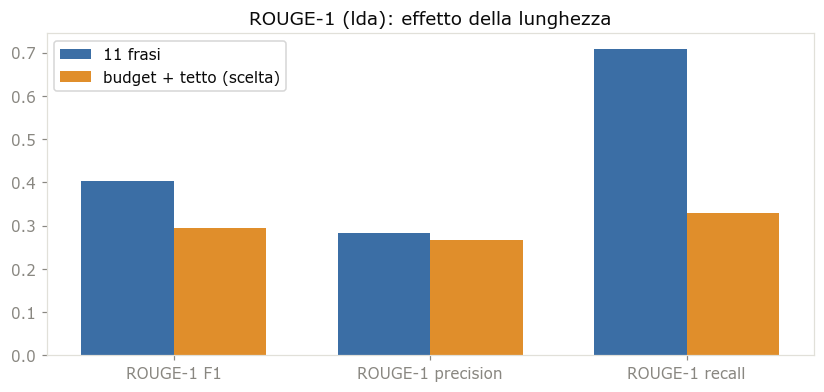

In [19]:
m11 = su.metriche_esempio(valutatore, riassunto_frasi, riferimento)
mbu = su.metriche_esempio(valutatore, riassunto_budget_tetto, riferimento)
m_scelta, m_altra = (m11, mbu) if MODALITA == 'frasi' else (mbu, m11)
assert np.isclose(m_scelta['rouge1_f1'], r1[0])   # coerente con il ROUGE-1 a mano della modalità scelta
et11 = '11 frasi' + (' ◀' if MODALITA == 'frasi' else '')
etbu = 'budget + tetto' + (' ◀' if MODALITA == 'budget' else '')

ordine_col = ['rouge1_f1', 'rouge1_p', 'rouge1_r', 'rouge2_f1', 'rouge2_p', 'rouge2_r',
              'rougeL_f1', 'rougeL_p', 'rougeL_r', 'bleu', 'meteor', 'parole_generate']
tab_metriche = pd.DataFrame({et11: m11, etbu: mbu}).loc[ordine_col]
tab_metriche.index = ['ROUGE-1 F1', 'ROUGE-1 precision', 'ROUGE-1 recall', 'ROUGE-2 F1', 'ROUGE-2 precision', 'ROUGE-2 recall',
                      'ROUGE-L F1', 'ROUGE-L precision', 'ROUGE-L recall', 'BLEU', 'METEOR', 'parole generate']
display(tab_metriche.round(3))

fig, ax = plt.subplots(figsize=(9, 3.8))
chiavi = ['rouge1_f1', 'rouge1_p', 'rouge1_r']
x = np.arange(len(chiavi)); w = .36
ax.bar(x - w / 2, [m11[k] for k in chiavi], w, label=et11.replace(' ◀', ' (scelta)'), color='#3b6ea5')
ax.bar(x + w / 2, [mbu[k] for k in chiavi], w, label=etbu.replace(' ◀', ' (scelta)'), color='#e08e2b')
ax.set_xticks(x); ax.set_xticklabels(['ROUGE-1 F1', 'ROUGE-1 precision', 'ROUGE-1 recall'])
ax.legend(); ax.set_title('ROUGE-1 (lda): effetto della lunghezza')
plt.show()

**Cosa abbiamo visto.** Con più parole la **recall** sale (si "pescano" più parole del
riferimento) ma la **precision** scende (molte parole in più non servono): la **F1** compensa i
due effetti ed è la metrica più onesta quando le lunghezze sono diverse. A parità di lunghezza
(budget), la differenza tra metodi riflette davvero la qualità della *selezione dei contenuti*.
Per LDA l'effetto è particolarmente forte, perché le 11 frasi sono molto più lunghe del riferimento.

## 12. Interpretazione dei risultati
Il commento seguente legge i numeri **di questa riga** (si aggiorna se cambi `ROW_ID` o `MODALITA`).

In [20]:
nome_altra = 'budget + tetto' if MODALITA == 'frasi' else '11 frasi'
dr, db = m_altra['rouge1_r'] - m_scelta['rouge1_r'], m_altra['rouge1_p'] - m_scelta['rouge1_p']
testo = f"""
**Riga {ROW_ID} — lda (K = {K} temi, seme {SEED}) — MODALITA `'{MODALITA}'`.**

- LDA ha ripartito le frasi in {K} temi; il più pesante ne raccoglie il {peso.max() / peso.sum():.0%} del peso. Le frasi
  scelte hanno in media {parole_frase[idx_scelti].mean():.0f} parole contro le {parole_frase.mean():.0f} della media del
  documento{': il criterio "θ più alto" favorisce le frasi lunghe.' if parole_frase[idx_scelti].mean() > parole_frase.mean() else '.'}
- Il riassunto ha {m_scelta['parole_generate']} parole contro le {len(riferimento.split())} del riferimento
  ({m_scelta['parole_generate'] / len(riferimento.split()):.1f}×): ROUGE-1 recall = **{m_scelta['rouge1_r']:.3f}**,
  precision = **{m_scelta['rouge1_p']:.3f}**, F1 = **{m_scelta['rouge1_f1']:.3f}**.
- Per confronto, con la modalità *{nome_altra}* ({m_altra['parole_generate']} parole) la recall {'sale' if dr > 0 else 'scende'} a
  **{m_altra['rouge1_r']:.3f}** (Δ = {dr:+.3f}) e la precision {'sale' if db > 0 else 'scende'} a **{m_altra['rouge1_p']:.3f}**
  (Δ = {db:+.3f}): F1 = **{m_altra['rouge1_f1']:.3f}**.
- ROUGE-2 F1 = {m_scelta['rouge2_f1']:.3f} (modalità scelta): molto più bassa di ROUGE-1, perché le sequenze di **due parole**
  consecutive in comune col riferimento *astratto* sono rare — è tipico dei metodi estrattivi.
"""
display(Markdown(testo))


**Riga 50492 — lda (K = 5 temi, seme 42) — MODALITA `'budget'`.**

- LDA ha ripartito le frasi in 5 temi; il più pesante ne raccoglie il 40% del peso. Le frasi
  scelte hanno in media 44 parole contro le 35 della media del
  documento: il criterio "θ più alto" favorisce le frasi lunghe.
- Il riassunto ha 174 parole contro le 168 del riferimento
  (1.0×): ROUGE-1 recall = **0.330**,
  precision = **0.266**, F1 = **0.294**.
- Per confronto, con la modalità *11 frasi* (528 parole) la recall sale a
  **0.709** (Δ = +0.379) e la precision sale a **0.282**
  (Δ = +0.016): F1 = **0.403**.
- ROUGE-2 F1 = 0.077 (modalità scelta): molto più bassa di ROUGE-1, perché le sequenze di **due parole**
  consecutive in comune col riferimento *astratto* sono rare — è tipico dei metodi estrattivi.


### Cosa portarsi a casa
1. **LDA è un modello generativo dei temi, usato per ripartire le frasi.** Ogni frase è una miscela di temi (θ), ogni
   tema una distribuzione sulle parole (β). Il riassunto si costruisce per **copertura**: quote di frasi per tema
   proporzionali al peso Σθ e, dentro il tema, le frasi con θ più alto. La lunghezza è *dentro* la selezione, non un
   taglio finale.
2. **Su frasi brevi θ è quasi un'etichetta.** Con pochi token per frase e priore sparso, ogni frase finisce
   quasi tutta su un tema: l'"appartenenza morbida" diventa un clustering. Più la frase è lunga più è netta, e il
   criterio "θ più alto" sceglie frasi **lunghe**: è coerente con le ~477 parole per riassunto del benchmark. Ma la
   nettezza delle frasi lunghe è in buona parte **circolare**: i temi sono stimati con quelle stesse frasi, e se una
   frase viene esclusa dall'addestramento la relazione si inverte (sezione 5). Verificato su una riga, non sull'intera split.
3. **L'inferenza è riproducibile ma non univoca.** Il fitting parte da un seme casuale e trova un ottimo locale: il
   benchmark fissa `random_state = 42`, ma con altri semi il set di frasi cambia. `N_TOPICS = 5` è una convenzione,
   non un valore tarato.
4. **Copre i temi, non evita le ripetizioni.** Manca un meccanismo come la deflazione di LSA o la penalità di MMR:
   due frasi quasi uguali dello stesso tema possono entrambe entrare se la quota lo permette.
5. **Il vantaggio di LDA nel benchmark era la lunghezza.** Sulle 5.588 righe di test, a 11 frasi, LDA ha la recall
   più alta dei cinque estrattivi dei notebook 15-17 (0,499) e METEOR 0,511 per via delle ~477 parole, ma la sua ROUGE-1 F1 (0,351) pareggia `lsa` e
   sta sotto `lsa_steinberger` (0,376). A **budget** (~230 parole dopo il tetto) la recall crolla a 0,348 e la F1 a
   0,338, l'ultima fra gli estrattivi: il vantaggio era interamente lunghezza.
6. **Il tetto delle metriche estrattive.** Il riferimento è astratto; le frasi estratte non lo riprodurranno mai.

### Esercizi proposti
- Cambia `ROW_ID` (es. 50501, 50523) e osserva come cambiano temi, quote e frasi scelte.
- Cambia `MODALITA` in `'frasi'` e rileggi le sezioni 8-12: quante parole ha il riassunto rispetto al riferimento?
  Cosa succede a recall, precision e F1?
- Prova `N_TOPICS = 2` e `N_TOPICS = 10`: le quote cambiano? I temi diventano più o meno leggibili? (Nella
  sezione 7 c'è la tabella dei valori intermedi.)
- Nella sezione 7 cambia `SEMI` (o `SEED` nella sezione 1): quali frasi restano? Sono le più lunghe?
- Con `MODALITA = 'budget'`, quali temi restano senza frasi? Cambia riga e guarda se succede ancora.
- Confronta le parole dei temi (sezione 4) con quelle dei concetti di LSA (sezione 13): quali sono più leggibili?

## Limiti dell'esperimento
I parametri di LDA nel benchmark sono **convenzioni o default della libreria, non iperparametri ottimizzati**. Quello che trovi sotto viene da esplorazioni su **questa riga** (19 frasi), senza intervalli di confidenza e non riprodotte sul test set: sono indicazioni, non risultati.

1. **`N_TOPICS = 5`.** Nessun motivo documentato. Attenzione all'accoppiamento: con i default `doc_topic_prior=None` e `topic_word_prior=None` scikit-learn pone α = η = 1/K, quindi **cambiare `N_TOPICS` cambia anche i priori** e la tabella della sezione 7 mescola i due effetti. Su questa riga il numero di temi cambia molto le quote ma poco le frasi scelte, perché dentro il tema vincono le frasi lunghe. Tarare `N_TOPICS` richiederebbe un insieme di validazione e un criterio: perplexity e coerenza dei temi misurano l'adattamento e la leggibilità, non la qualità del riassunto.
2. **α e η (`doc_topic_prior`, `topic_word_prior`).** Mai impostati: valgono 1/K = 0,2. Il priore sparso su α è il motivo per cui, con frasi di pochi token, θ è quasi «dura» (sezione 5). Variando α il θ massimo mediano passa da 0,95 (α = 0,2) a 0,74 (α = 1,0), e in questa versione di scikit-learn α non può superare 1. **L'effetto sulle frasi scelte e sulle metriche non è stato misurato, e η non è stato esplorato.** Il «numero basso di temi per frase» è in buona parte la conseguenza di un default.
3. **`random_state = 42`.** Rende il risultato riproducibile, ma il fitting si ferma in un ottimo **locale** che dipende dal seme. Nella sezione 7 la somiglianza tra i set scelti con semi diversi è ~0,64 e solo 5 frasi su 11 sono scelte sempre. Il benchmark fa **una run per riga**: la varianza dovuta al seme non è stata quantificata sul test set (servirebbero più semi per riga e un intervallo). Differenze piccole fra metodi, come la F1 di `lda` e `lsa` entrambe a 0,351, vanno lette tenendo conto di questo rumore.
4. **Due limiti strutturali.** θ è stimata sulle stesse frasi usate per addestrare (la verifica leave-one-out della sezione 5 mostra che questo gonfia la nettezza delle frasi lunghe), e ogni riga ha il suo modello su 20-70 frasi brevi, mentre LDA è pensato per collezioni di migliaia di documenti. Addestrare i temi su un corpus più grande e inferire poi θ sulle frasi del cluster è un'alternativa **non provata** in questo studio.

I numeri del benchmark citati sopra restano quelli pubblicati (`N_TOPICS = 5`, default di scikit-learn, seme 42). Gli esercizi qui sopra permettono di rifare le prove su questa riga.

## 13. (Extra) LDA e LSA a confronto
LSA ([notebook 15](15_lsa_didattico.ipynb)) e LDA sembrano parenti: entrambe partono da una matrice
frase × termine, entrambe cercano un piccolo numero di **temi latenti** senza supervisione, entrambe usano
solo le frasi del cluster. Ma ragionano in modo diverso. In sintesi:

| | **LSA** (notebook 15) | **LDA** (notebook 17) |
|---|---|---|
| Natura | **fattorizzazione algebrica** (SVD): la migliore approssimazione di rango K di A ai minimi quadrati, senza ipotesi probabilistiche | modello **generativo probabilistico** con priori di Dirichlet, stimato per inferenza variazionale |
| Matrice di partenza | pesi **TF-IDF** (reali) | **conteggi** interi (bag-of-words) |
| Il "tema" | **concetto**: direzione nello spazio dei termini, ortogonale alle altre; carichi con segno arbitrario | **topic**: distribuzione di probabilità sulle parole (≥ 0, somma 1); i topic possono sovrapporsi |
| La frase | vettore **z** in ℝᴷ con componenti col segno (U·Σ) | **θ** sul simplesso: K proporzioni ≥ 0 che sommano a 1 |
| Leggibilità | si guarda il valore assoluto dei carichi | i topic si leggono direttamente |
| "Importanza" di una frase | la **lunghezza** ‖z‖ (salienza): quanto la frase porta sui concetti forti | **nessuna**: θ dice *a quale* tema appartiene, non quanto la frase conti. L'importanza è del tema (Σθ) |
| Selezione | classifica **globale** per salienza (top-k) o greedy con **deflazione** (anti-ridondanza) | **quote per tema** proporzionali al peso; dentro il tema, il θ più alto → **copertura** per costruzione |
| Ridondanza | gestita solo da `lsa_steinberger` | non gestita; l'unico antidoto è la copertura dei temi |
| Lunghezza del riassunto | un ordine: la lunghezza è un taglio | entra nelle quote: 11 frasi e budget sono selezioni diverse |
| Determinismo | SVD deterministica (a meno del segno) | dipende da `random_state`: ottimo locale |
| Iperparametri | `K_LATENTE` | `N_TOPICS`, più i priori α, η e le iterazioni |
| Debolezza osservata | favorisce frasi **corte e isolate** (concetti con σ = 1) | favorisce frasi **lunghe** (θ più netto sulle frasi usate per addestrare, in parte per circolarità) |

**Parentela concettuale.** LDA è la versione bayesiana di *pLSA* (Hofmann, 1999), a sua volta una riformulazione
probabilistica di LSA: stessa forma P(w | frase) = Σₖ P(w | k)·P(k | frase) — che sulla matrice è un prodotto
θ·β, come U·Σ·Vᵀ in LSA — ma con vincoli di non-negatività, probabilità e priori al posto di ortogonalità e minimi
quadrati. È il motivo per cui nel documento-guida (§3.6) LDA è coperta "indirettamente via NMF/LSA".

**Il compromesso pratico.** LSA dà un punteggio per frase (e quindi un ordine) ma temi poco leggibili; LDA dà
temi leggibili e una copertura garantita, ma nessun punteggio di importanza e un risultato che dipende dal seme.
Su cluster piccoli (~20 frasi) nessuno dei due ha molta statistica su cui lavorare.

Vediamolo sulla stessa riga: parole dei temi, frasi nello spazio dei due modelli, selezioni e metriche.

(a) Parole più "pesanti" per tema (LSA: |carico|; LDA: probabilità β):
  LSA C0: event, facebook, page, photo, kiss, john
  LDA T0: taken, christian, boyfriend, 2008, episode, kisses
  LSA C1: john, snow, considered, richard, used, mild
  LDA T1: just, event, paul, boing, hey, people
  LSA C2: kissing, promote, event, just, page, paul
  LDA T2: facebook, event, photo, page, removed, snow
  LSA C3: people, confused, gay, christian, picture, episode
  LDA T3: kiss, gay, promote, london, pub, protest
  LSA C4: confused, people, gay, considered, kisses, october
  LDA T4: richard, kiss, post, john, photo, used


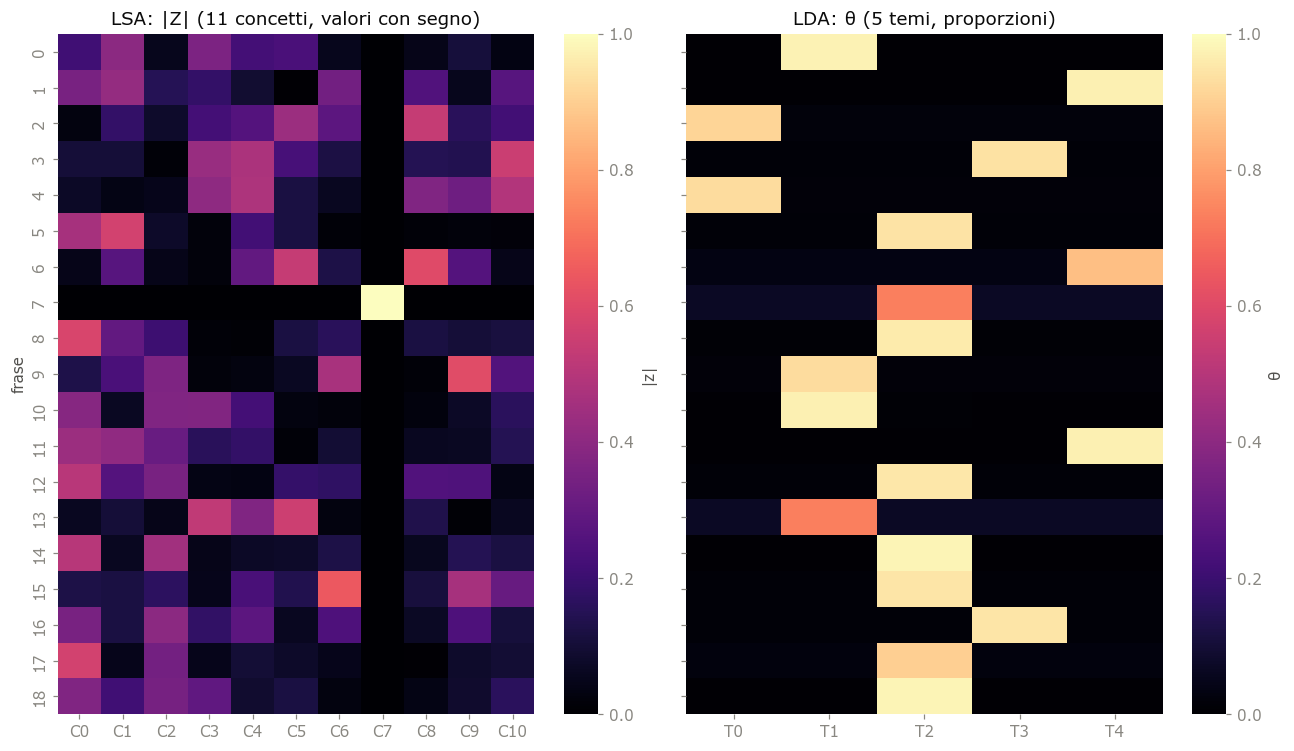

In [21]:
# --- LSA: copia fedele da notebooks/15_lsa.ipynb (verificata nel notebook didattico 15) ----------------
EPS = 1e-12
K_LATENTE = 11              # come il benchmark: dimensione dello spazio latente di LSA
K_ORDINE_BUDGET = 50        # lunghezza massima dell'ordine in modalità 'budget'

def seleziona_topk(Z, n_sentences):
    salienza = np.linalg.norm(Z, axis=1)
    return [int(i) for i in np.argsort(-salienza)[:n_sentences]]

def seleziona_deflazione(Z, n_sentences):
    R = np.array(Z, dtype=float, copy=True)
    scelti = []
    for _ in range(min(n_sentences, len(R))):
        lunghezze = np.linalg.norm(R, axis=1)
        lunghezze[scelti] = -1.0
        i = int(np.argmax(lunghezze))
        if lunghezze[i] <= EPS:
            break
        scelti.append(i)
        u = R[i] / np.linalg.norm(R[i])
        R -= np.outer(R @ u, u)
    if len(scelti) < min(n_sentences, len(Z)):
        for i in np.argsort(-np.linalg.norm(Z, axis=1)):
            if int(i) not in scelti:
                scelti.append(int(i))
            if len(scelti) >= min(n_sentences, len(Z)):
                break
    return scelti
# ----------------------------------------------------------------------------------------------------

A = TfidfVectorizer(stop_words='english').fit_transform(frasi)
K_L = max(1, min(K_LATENTE, min(A.shape) - 1))
svd = TruncatedSVD(n_components=K_L, random_state=SEED)
Z = svd.fit_transform(A)
Vt = svd.components_
salienza_lsa = np.linalg.norm(Z, axis=1)

# --- (a) i "temi": concetti di LSA vs topic di LDA ---
N_CONFR = min(5, K, K_L)
vocabolario_lsa = TfidfVectorizer(stop_words='english').fit(frasi).get_feature_names_out()
righe = {}
for t in range(N_CONFR):
    righe[f'LSA C{t}'] = ', '.join(vocabolario_lsa[j] for j in np.argsort(-np.abs(Vt[t]))[:6])
    righe[f'LDA T{t}'] = ', '.join(vocabolario[j] for j in np.argsort(-beta[t])[:6])
print('(a) Parole più "pesanti" per tema (LSA: |carico|; LDA: probabilità β):')
for k_, v_ in righe.items():
    print(f'  {k_}: {v_}')

# --- (b) le frasi nei due spazi ---
fig, assi = plt.subplots(1, 2, figsize=(12, 0.27 * N + 1.8), sharey=True)
sns.heatmap(np.abs(Z), cmap='magma', xticklabels=[f'C{k}' for k in range(K_L)], yticklabels=range(N),
            cbar_kws={'label': '|z|'}, ax=assi[0])
assi[0].set_title(f'LSA: |Z| ({K_L} concetti, valori con segno)'); assi[0].set_ylabel('frase')
sns.heatmap(theta, cmap='magma', vmin=0, vmax=1, xticklabels=[f'T{t}' for t in range(K)], yticklabels=range(N),
            cbar_kws={'label': 'θ'}, ax=assi[1])
assi[1].set_title(f'LDA: θ ({K} temi, proporzioni)')
plt.tight_layout(); plt.show()

**Cosa abbiamo visto.** Le frasi, nei due modelli, hanno forma molto diversa: in LSA un vettore con molte componenti
di intensità variabile (la cui lunghezza è la salienza), con l'eccezione della frase 7 ("Oh the irony"), che è un
concetto a sé e si accende su una sola colonna; in LDA quasi una sola cella accesa per riga. Lo si vede anche
nei temi: il concetto C0 di LSA somiglia al topic T2 (Facebook, evento, foto), ma i concetti successivi mescolano
parole di frasi diverse e hanno segno arbitrario, mentre i topic di LDA sono per lo più più facili da leggere
(non sempre: T1 è un miscuglio) e a patto di ricordare che un altro seme li rimescola.

Ora confrontiamo cosa **scelgono** i due metodi (più `lsa_steinberger`) sulla stessa riga, con la `MODALITA` scelta,
e se la lunghezza della frase "spiega" il punteggio di ciascuno.

Stessa riga, stessa lunghezza per tutti (11 frasi oppure budget + tetto):


frasi  parole  ROUGE-1 F1  precision  recall  frasi in comune con lda
modalità metodo                                                                                
frasi    lsa                 11     269       0.368      0.304   0.466                        4
         lsa_steinberger     11     312       0.391      0.309   0.534                        5
         lda                 11     528       0.403      0.282   0.709                       11
budget ◀ lsa                  9     185       0.400      0.369   0.437                        1
         lsa_steinberger      9     185       0.400      0.369   0.437                        1
         lda                  4     174       0.294      0.266   0.330                        4

  frasi |              lsa: frasi [1, 2, 3, 4, 5, 6, 7, 9, 12, 13, 15]
  frasi |  lsa_steinberger: frasi [1, 2, 3, 4, 6, 7, 9, 12, 13, 14, 15]
  frasi |              lda: frasi [0, 1, 4, 8, 10, 11, 12, 14, 15, 16, 18]
 budget |              lsa: frasi [2, 3, 4, 6, 7, 9, 12, 13, 15]
 budget |  lsa_steinberger: frasi [2, 3, 4, 6, 7, 9, 12, 13, 15]
 budget |              lda: frasi [0, 4, 16, 18]


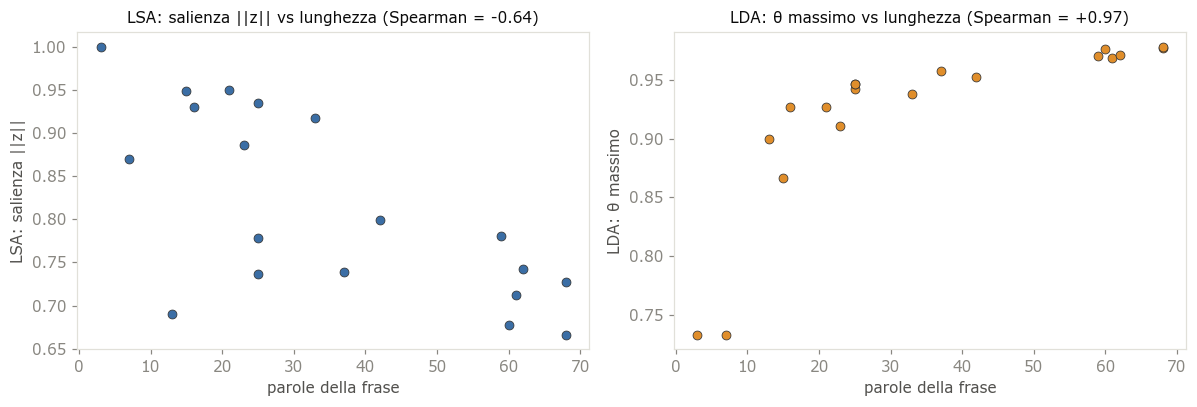

correlazione di Spearman con la lunghezza della frase: LSA salienza -0.64 | LDA θ massimo +0.97


In [22]:
n_ord = min(N, K_ORDINE_BUDGET)       # l'ordine lungo: 'frasi' ne prende il prefisso di 11 (proprietà verificata nel 15)
ordini = {'lsa': seleziona_topk(Z, n_ord), 'lsa_steinberger': seleziona_deflazione(Z, n_ord)}

def scegli(ordine, modo):
    if modo == 'frasi':
        sel = ordine[:N_SENTENCES] if N > N_SENTENCES else list(range(N))
        return list(sel), ' '.join(frasi[i] for i in sorted(sel))
    sel = su.seleziona_per_budget(frasi, ordine, budget)
    return list(sel), su.tronca_parole(' '.join(frasi[i] for i in sorted(sel)), tetto)

conf = {modo: {v: scegli(o, modo) for v, o in ordini.items()} for modo in ('frasi', 'budget')}
conf['frasi']['lda'] = (list(idx_frasi), riassunto_frasi)                 # già calcolati nelle sezioni 8-9
conf['budget']['lda'] = (list(idx_budget), riassunto_budget_tetto)
metodi = ['lsa', 'lsa_steinberger', 'lda']

righe = []
for modo in ('frasi', 'budget'):
    for v in metodi:
        m_ = su.metriche_esempio(valutatore, conf[modo][v][1], riferimento)
        righe.append({'modalità': modo + (' ◀' if modo == MODALITA else ''), 'metodo': v, 'frasi': len(conf[modo][v][0]),
                      'parole': m_['parole_generate'], 'ROUGE-1 F1': round(m_['rouge1_f1'], 3),
                      'precision': round(m_['rouge1_p'], 3), 'recall': round(m_['rouge1_r'], 3),
                      'frasi in comune con lda': len(set(conf[modo][v][0]) & set(conf[modo]['lda'][0]))})
print('Stessa riga, stessa lunghezza per tutti (11 frasi oppure budget + tetto):')
display(pd.DataFrame(righe).set_index(['modalità', 'metodo']))
for modo in ('frasi', 'budget'):
    for v in metodi:
        print(f'{modo:>7} | {v:>16}: frasi {sorted(conf[modo][v][0])}')

# --- il bias di lunghezza dei due punteggi ---
sp_lsa = pd.Series(salienza_lsa).corr(pd.Series(parole_frase), method='spearman')
sp_lda = pd.Series(max_theta).corr(pd.Series(parole_frase), method='spearman')
fig, assi = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, y, nome, sp, c in ((assi[0], salienza_lsa, 'LSA: salienza ||z||', sp_lsa, '#3b6ea5'),
                           (assi[1], max_theta, 'LDA: θ massimo', sp_lda, '#e08e2b')):
    ax.scatter(parole_frase, y, s=34, color=c, edgecolors='#333', linewidths=.5)
    ax.set_xlabel('parole della frase'); ax.set_ylabel(nome)
    ax.set_title(f'{nome} vs lunghezza (Spearman = {sp:+.2f})', fontsize=10)
plt.tight_layout(); plt.show()
print(f'correlazione di Spearman con la lunghezza della frase: LSA salienza {sp_lsa:+.2f} | LDA θ massimo {sp_lda:+.2f}')

**Cosa abbiamo visto.** Sulla riga 50492 i due punteggi hanno **segno opposto** rispetto alla lunghezza: la salienza di
LSA scende con le parole (correlazione negativa: sceglie frasi corte e isolate), il θ massimo di LDA sale (positiva:
sceglie frasi lunghe e nette). Gli insiemi di frasi scelti coincidono poco (la tabella mostra quante ne
hanno in comune con LDA: 4-5 su 11 a 11 frasi, 1 a budget) e, a 11 frasi, i riassunti di LDA sono molto più lunghi; a budget le lunghezze sono
confrontabili per costruzione, e quello che resta è la differenza di contenuto. Sono due modi di sbagliare **in
direzioni opposte**, entrambi legati a come ciascun modello tratta le frasi brevi: LSA le trasforma in concetti a
sé (σ = 1), LDA le lascia più incerte (θ meno netto, sul priore).

⚠️ Una cautela: su questa riga, a 11 frasi, LDA ha anche la F1 **più alta** (0,403 contro 0,368 e 0,391), mentre nel
benchmark la sua F1 pareggia `lsa` e sta sotto `lsa_steinberger`. Una riga non è un benchmark. A budget, invece, la
riga concorda con il benchmark: LDA è ultima.

Nel benchmark il bias si legge nelle lunghezze: ~249-257 parole per le due varianti LSA contro ~477 per LDA a 11
frasi. Qui sotto i numeri aggregati, letti dai file delle metriche del progetto.

In [23]:
import json

righe = []
for ambito in ('test', 'test_budgetref'):
    for v in ('lsa', 'lsa_steinberger', 'lda'):
        percorso = P['metrics_dir'] / f'{v}_{ambito}_aggregate.json'
        if not percorso.exists():
            continue
        o = json.loads(percorso.read_text(encoding='utf-8'))['overall']
        righe.append({'ambito': ambito, 'metodo': v, 'parole': round(o['parole_generate']), 'ROUGE-1 F1': round(o['rouge1_f1'], 3),
                      'precision': round(o['rouge1_p'], 3), 'recall': round(o['rouge1_r'], 3)})
if righe:
    print('Benchmark su tutta la split di test (media sulle righe valutate):')
    display(pd.DataFrame(righe).set_index(['ambito', 'metodo']))
else:
    print('File delle metriche non disponibili (serve results/metrics/ del repository): sezione saltata.')

Benchmark su tutta la split di test (media sulle righe valutate):


parole  ROUGE-1 F1  precision  recall
ambito         metodo                                                
test           lsa                 249       0.351      0.384   0.357
               lsa_steinberger     257       0.376      0.358   0.419
               lda                 477       0.351      0.280   0.499
test_budgetref lsa                 215       0.350      0.395   0.322
               lsa_steinberger     215       0.369      0.376   0.366
               lda                 230       0.338      0.332   0.348

**Cosa abbiamo visto.** A 11 frasi LDA ha la recall più alta ma la F1 allo stesso livello di `lsa` e sotto
`lsa_steinberger`: la lunghezza gonfia la recall senza migliorare l'equilibrio. A budget, cioè a parità di
lunghezza, la F1 di LDA (0,338) scende sotto entrambe le varianti di LSA (0,350 e 0,369), mentre la recall (0,348)
sta tra le due. Conclusione di metodo: i due approcci
sono **complementari nelle idee** (LDA: copertura dei temi; LSA: salienza e, con la deflazione, anti-ridondanza)
ma, su cluster così piccoli, la copertura tematica di LDA non basta a battere la selezione per salienza con
anti-ridondanza di `lsa_steinberger`. Una combinazione sensata — quote per tema più deflazione dentro il tema —
non è stata provata in questo studio.